# [1] 11 The next-event forecast

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. The forecast (400 timing draws x 5 bootstrap refits per model, catalogue and
aperiodicity branch) takes a few minutes.
```

**What this notebook does.** Everything the paper predicts is here, in one place, from the event
catalogues (04, 09) and notebook 10's rain products:

1. **The repeat intervals, ONE definition** (the only notebook that computes them; 04 registered
   point-onset intervals until 2026-10-06): for each of `n_timing` draws of the onsets, uniform within
   their windows (no midpoints), the sample mean and sample SD (ddof = 1) of the record's intervals;
   both averaged over the draws; COV = SD / mean; "+/-" is 1 SD of the intervals (not a standard
   error). Per record (`11_<rec>_interval_mean_yr`, `_sd_yr`, `_cov`, `_n_intervals`, `_n_events`):
   InSAR (5 events, 4 intervals), the bimonthly-era HRKT array record without the interval that
   spans Loma Prieta (`aa_dense_nolp`: 9 events, 7 intervals) and with it (`aa_dense_withlp`: 8
   intervals), and the combined record (`merged`: 14 events, 11 intervals; no interval across
   the unobserved 2006-2017 gap, none across Loma Prieta). Fig 3C draws the same numbers.
2. **Renewal forecast** of the next onset: the intervals of each draw fitted by exponential,
   lognormal, Weibull, BPT and Gaussian models with a parametric bootstrap, conditional on no event
   through the last observation, `forecast_last_obs_date` (TulePond_filepaths: the last descending
   acquisition of the CSLC + Dolphin extension check, 2026-10-05). The fitted BPT aperiodicity is
   registered as `11_<rec>_bpt_alpha` (the inverse-Gaussian MLE, NOT the sample COV of 1.). The
   paper's InSAR record still ends at the data end, the last acquisition on both tracks (read from
   03's fp_ts), registered as `11_data_end`.
3. **The Working Group aperiodicities** (WGCEP 1999, USGS OFR 99-517, printed p16: alpha 0.3, 0.5
   and 0.7 as weighted branches, never a fitted alpha): the BPT forecast of each record with alpha
   FIXED at each branch (only the mean refitted), the branches mixed with the weights 0.2, 0.6, 0.2
   (the report's three-way branch convention, App. C printed p31; the alpha weights themselves are
   not printed in OFR 99-517, so two other weightings are shown and the mixture's P is insensitive
   to them). For the InSAR record also the fitted-alpha forecast with alpha drawn from its
   chi-square pivot (the uncertainty of alpha from four intervals), its 95 % CI, and the
   falsification dates: when the fitted-alpha model's conditional chance of no event falls to 5 %
   and to 1 %.
4. **The InSAR clock** in closed form (mean interval, t-based prediction interval), on the same
   onset draws as 1.
5. **Fig 3** and **the prediction statement**, combining the recurrence windows with the calendar
   window of the onsets (from 10's `rain_conditioning_summary.csv`; the rainfall-conditioning tests
   themselves moved to 10_rain_seasonality on 2026-10-06).

Loma Prieta: the array forecast is given both without and with the interval spanning the 1989
earthquake (keys `_nolp` / `_withlp`), as WGCEP 1999 ran its BPT calculations with and without the
stress-interaction clock changes in parallel (printed p17); the paper quotes `_nolp` (Lienkaemper et
al. 1997: the creep suppression after Loma Prieta on the southern Hayward fault).

ONE wet season (Dani 2026-10-05: October to April), `TulePond_filepaths.wet_season_months` = (first
month, last month), shared with 10_rain_seasonality's onset-season count (this notebook checks it against
the months 10 saved). `forecast_wet_season` is that season in the first water year whose season ends after
the last observation (WY2027: every "P(WY2027 wet season)").

**Quantiles beyond the forecast grid.** The forecast curves are evaluated on a daily grid (`grid`, derived
in [8] from the data: from the first 1 January after the last onset to `grid_span_means` of the longest
mean interval past the last observation). A mixture curve that never reaches a quantile on the grid has
no date: `quantile_date` returns NaN and the quantile is written and registered as '> <grid end>', never
as the grid end itself. Each forecast row also carries `p_by_grid_end`.

PREPUB: Ported from `Hayward_DISP-S1/analysis/run21_recurrence_forecast.py`; until 2026-09-24 this was the
PREPUB: second half of the old notebook 09_seasonality_forecast. Its old registry rows (`10_issue_date`,
PREPUB: `10_insar_*`, `10_aa_dense_*`, from `10_seasonality_forecast_v2`) are RETIRED in registry.txt.
PREPUB: Retired 2026-10-06 (no longer registered here): `11_insar_cov` and `11_*_fig3c_*` (folded into the one
PREPUB: interval definition), `11_aa_dense_*` (renamed `11_aa_dense_withlp_*`), `11_*_p_by_end_2027` (quoted
PREPUB: nowhere), and the rainfall-conditioning keys `11_onset_*`, `11_wy_*`, `11_cum_at_*`, `11_frac_at_*`,
PREPUB: `11_ruleA/B_*`, `11_rain_sweep_*` (now 10_rain_seasonality's `10_*`). `11_<rec>_interval_cov` was the
PREPUB: BPT alpha until 2026-10-06; it is now the sample COV (the alpha is `11_<rec>_bpt_alpha`).

**Inputs**: 03 `fp_ts.csv` (the data end), 04 `section_lengths.csv` and 04's registered 90 % band-stack
steps (`04_band90_step_<yr>_mm` and their CIs, read back from `registry.csv`, 04's latest run: the
prediction statement's LOCATION and MAGNITUDE), 04 `creep_events.csv` (InSAR onset windows:
`onset_lo`, the last acquisition before the step, which is 04's step epoch, to `onset_hi`, the
first acquisition after it), 09 `hrkt_aa_events.csv` (array onset windows `onset_lo` to
`onset_hi`; `onset_mid` = the window midpoint, for labels, plot positions and sort keys only) and
`aa_insar_stacks.csv`, 10 `fig3_rain_panel.npz` (with 10's wet-season months), `fig3_onset_windows.csv`
and `rain_conditioning_summary.csv`, the HRKT array file.

**Outputs** (`outputs/11_forecast/`): `recurrence_forecast_models.csv` (every record x model: interval
statistics, quantiles, P(wet season)), `recurrence_intervals.csv` (the one definition of 1., per record),
`recurrence_forecast_wg99.csv` (every record x aperiodicity branch, the mixtures and the InSAR alpha-pivot
forecast), `prediction_statement.txt`, the stats sidecar `11_forecast_stats.txt`, registry rows `11_*`.

**Figures**: the paper's Fig 3 (`fig3_history_forecast_ntiming400_nboot5_issue<date>`: A HRKT history, B
onsets over the rain, C repeat intervals, D the forecast); the five renewal models
(`qc11_renewal_models_single_fits`, working).

**What to check.** The InSAR clock gives the next event about mid December 2026 (`11_next_clock_date`,
95 % prediction interval `11_pi95_*`, whose lower end lies before the last observation: the clock is
unconditional, do not quote it as a forecast window); the InSAR BPT 5-95 % window (`11_insar_bpt_q05`,
`_q95`) sits inside the coming wet season ONLY with the fitted alpha (~0.035); with the Working Group
aperiodicities (`11_insar_bpt_wg99_p_wet_wy2027`) and on the array and merged records the wet-season
probability is far lower; the mixture's P moves by about 0.01 between weightings.
Every number is registered in the last cell (`11_*`).

In [1]:
# [2]
import calendar
import os

import insar_utils as utils
from TulePond_filepaths import common_paths, paths_out, repo_dir, forecast_issue_date, forecast_last_obs_date
from TulePond_filepaths import wet_season_months as wet_season_first_last, aa_dense_window_days, loma_prieta_yr, paper_band_frac

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
from scipy import stats                          # the renewal distributions
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator

## [3] Paths and parameters

The forecast settings, the Working Group aperiodicity branches, the wet season and the input files.

**Random numbers.** `seed` starts every generator, each a fresh `np.random.default_rng(seed)`: the
forecast of [26] (one generator feeding, in order, each catalogue's interval draws and then its five
model forecasts), each aperiodicity branch and the alpha-pivot forecast of [28] (one generator each, so the
three branches use the SAME onset and bootstrap draws: common random numbers, the mixture differs only by
alpha). The closed-form clock of [30] has no generator of its own: it reads the InSAR onset draws of [26].

In [2]:
# [4]
notebook = "11_forecast"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)


# the forecast
loma_prieta = loma_prieta_yr   # 17 Oct 1989 (TulePond_filepaths, as 09 and 10)
n_timing = 400                 # timing draws: onsets drawn uniformly in their windows
n_boot = 5                     # bootstrap refits per timing draw (per catalogue and model): 400 x 5 = 2000 curves per mean
#                                forecast curve, enough for a mean cdf; a Monte Carlo setting, not a statistical one (the
#                                parametric bootstrap cannot widen alpha beyond its biased-low refits: [28] does that)
seed = 7                       # every generator starts from it (see above)
# The forecast is conditioned on no event through the last observation, forecast_last_obs_date
# (TulePond_filepaths: the last descending acquisition of the CSLC + Dolphin extension check,
# extension_2026-09/RESULT.md, 2026-10-05; Dani 2026-10-05). The paper's InSAR record ends earlier, at
# the data end (the end of the fault-parallel series, read from the data below), and stays the record end.
# forecast_issue_date is only the date the statement was first written (fixed, so the file names hold);
# nothing is claimed for the months after the last observation.
models = ["exponential", "lognormal", "weibull", "bpt", "gaussian"]
resolvable_days = aa_dense_window_days   # array windows longer than this do not constrain the season (TulePond_filepaths: 09's bimonthly era)
min_interval_yr = 0.05         # bootstrap intervals shorter than this are clipped to it (counted and reported)
max_degenerate_fraction = 0.01   # at most this share of the forecast curves may come from a refit with zero survival
grid_span_means = 4.0          # the forecast grid runs this many of the longest mean interval past the last observation
#                                (the exponential's 95 % lies 3.0 means after it, -ln 0.05; one more mean leaves room for
#                                the bootstrap spread of the mean); its start and end are derived in [8]

# the Working Group aperiodicities: WGCEP (1999), "Earthquake Probabilities in the San Francisco Bay Region: 2000 to
# 2030 - A Summary of Findings", USGS Open-File Report 99-517, printed p16: "For the aperiodicity, WG99 used three
# (weighted) values: 0.3, 0.5, and 0.7" (representative of the 37 sequences of Ellsworth et al.). The alpha weights
# are NOT printed in the report; the weights below are its stated convention for a three-way branch point (App. C,
# printed p31: "branch weights of 0.2, 0.6, and 0.2 ... corresponding roughly to a confidence interval of one
# standard deviation"). The alternative weightings are a sensitivity check only (equal weights, and 0.2/0.5/0.3, the
# one other three-way weighting in the report, Table 2, for a different quantity); WG99 mixes branch PROBABILITIES
# by weighted mean (printed p18), so the branch cdfs are mixed with the weights.
wg99_alpha_branches = (0.3, 0.5, 0.7)
wg99_alpha_weights = (0.2, 0.6, 0.2)
wg99_alternative_weights = {"equal": (1 / 3, 1 / 3, 1 / 3), "0.2/0.5/0.3": (0.2, 0.5, 0.3)}
assert abs(sum(wg99_alpha_weights) - 1) < 1e-12 and all(abs(sum(w) - 1) < 1e-12 for w in wg99_alternative_weights.values())
# falsification: the dates by which the fitted-alpha InSAR model's conditional chance of NO event (its survival,
# 1 - the conditional cdf) falls to these levels; no event by then rejects that model at 1 - level
falsification_levels = (0.05, 0.01)

# the wet season, (first month, last month): ONE definition with 10_rain_seasonality's onset count (Dani 2026-10-05:
# October to April), TulePond_filepaths.wet_season_months (imported above: a missing value stops the import).
# forecast_wet_season (its dates in the coming water year) is set once the last observation is read, cell [8].
wet_season_source = "TulePond_filepaths.wet_season_months"
assert len(wet_season_first_last) == 2 and all(int(m) == m and 1 <= m <= 12 for m in wet_season_first_last), \
    f"wet_season_months must be (first month, last month), got {wet_season_first_last}"
first_wet_month, last_wet_month = (int(m) for m in wet_season_first_last)
wet_season_months = []                     # the months of the season in order, wrapping across the new year
for k in range((last_wet_month - first_wet_month) % 12 + 1):
    wet_season_months.append((first_wet_month - 1 + k) % 12 + 1)
wet_months_text = f"{calendar.month_abbr[first_wet_month]}-{calendar.month_abbr[last_wet_month]}"     # e.g. 'Oct-Apr'

# the prediction statement's LOCATION and MAGNITUDE: 04's measured extents and the paper's band stack
magnitude_band_pct = int(round(100 * paper_band_frac))   # 04's band_main (TulePond_filepaths paper_band_frac 0.90): the peak slip zone the steps are quoted on
magnitude_band = f"band{magnitude_band_pct}"      # 04's name for it (section_lengths.csv row tulepond_band90, keys 04_band90_*)

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
section_lengths_file = os.path.join(paths_out["04_event_detection"], "section_lengths.csv")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_events_file = os.path.join(paths_out["09_alignment_arrays"], "hrkt_aa_events.csv")
aa_stacks_file = os.path.join(paths_out["09_alignment_arrays"], "aa_insar_stacks.csv")
rain_panel_file = os.path.join(paths_out["10_rain_seasonality"], "fig3_rain_panel.npz")
windows_file = os.path.join(paths_out["10_rain_seasonality"], "fig3_onset_windows.csv")
rain_summary_file = os.path.join(paths_out["10_rain_seasonality"], "rain_conditioning_summary.csv")
hrkt_file = os.path.join(common_paths["aa_dir"], "HRKT.csv")

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, section_lengths_file, events_file, aa_events_file, aa_stacks_file, rain_panel_file, windows_file, rain_summary_file, hrkt_file)

Registry for 11_forecast: run 759ae165, git 6168603+


## [5] Functions: dates and water years

Decimal years to calendar dates and back, and the wet season of a water year.

In [3]:
# [6]
def decyear(dates):
    """Decimal year of a DatetimeIndex, fraction of the actual year length."""
    dates = pd.DatetimeIndex(dates)
    year_start = pd.to_datetime(dates.year.astype(str) + "-01-01")
    next_year_start = pd.to_datetime((dates.year + 1).astype(str) + "-01-01")
    return dates.year + (dates - year_start) / (next_year_start - year_start)


def decyear_to_date(years):
    """The calendar day nearest to each decimal year, as a DatetimeIndex (an acquisition's own day)."""
    out = []
    for value in np.atleast_1d(np.asarray(years, float)):
        out.append(utils.decimal_year_to_day(value))
    return pd.DatetimeIndex(out)


def ymd(year):
    """One decimal year as 'YYYY-MM-DD'."""
    return decyear_to_date(year)[0].strftime("%Y-%m-%d")


def wet_season_of(wy):
    """(first day, last day) of the wet season (wet_season_months) of water year wy, as 'YYYY-MM-DD'; a month from
    October on belongs to the calendar year before the water year's."""
    first = pd.Timestamp(year=wy - 1 if first_wet_month >= 10 else wy, month=first_wet_month, day=1)
    last = pd.Timestamp(year=wy - 1 if last_wet_month >= 10 else wy, month=last_wet_month, day=1) + pd.offsets.MonthEnd(0)
    return first.strftime("%Y-%m-%d"), last.strftime("%Y-%m-%d")

## [7] Load: the event catalogues, the forecast dates and grid, 10's rain summary

The catalogues: InSAR events from 04 (window `onset_lo` to `onset_hi`; `onset_lo` is
the last acquisition before the step); the HRKT array events from 09, all from the bimonthly era
(09 runs the detector only there), whose windows of `aa_dense_window_days` (130 d) or less resolve the
season (asserted); and the merged record, the bimonthly-era array events and the InSAR events, with the
years between the last array event (2006) and the first InSAR event (2017) treated as unobserved
(annual surveys from mid-2007): no interval is formed across them, the clock simply restarts with
the first InSAR detection. There are no array detections after 2006.

The forecast grid (daily) is derived here: it starts on the first 1 January after the last InSAR onset
window opened (`onset_lo`; every conditional curve is zero until the last observation, which must lie on the grid,
asserted) and ends on the 1 January after the last observation plus `grid_span_means` times the
longest mean interval of the four catalogues (point onsets: window midpoints).

10's `rain_conditioning_summary.csv` gives part (3) of the prediction statement and the last Fremont
day of its data line (read, never recomputed here).

In [4]:
# [8]
creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"].sort_values("onset_lo").reset_index(drop=True)
insar_events["onset_mid"] = 0.5 * (insar_events.onset_lo + insar_events.onset_hi)     # as 09's: sort key and plot position only
aa_dense = pd.read_csv(aa_events_file)
assert (aa_dense.window_days <= resolvable_days).all(), f"09 returned an array window longer than {resolvable_days} d"
# every catalogue carries a `src` column; an interval is only formed between two events of the same source, so the
# merged catalogue never bridges 2006 to 2017, when the arrays were surveyed annually and the section was unobserved
# by the clock's standard (Dani, 2026-09-24). The clock restarts with the first InSAR detection.
insar_events = insar_events.assign(src="InSAR")
aa_dense = aa_dense.assign(src="AA")
merged_events = pd.concat([aa_dense[["onset_lo", "onset_hi", "onset_mid", "src"]], insar_events[["onset_lo", "onset_hi", "onset_mid", "src"]]])
merged_events = merged_events.sort_values("onset_mid").reset_index(drop=True)
# name -> (catalogue, drop the Loma Prieta-spanning interval?); the combined record also leaves out the Loma
# Prieta-spanning interval (Dani, 2026-09-29)
catalogues = {"A_insar": (insar_events, False), "B_aa_dense": (aa_dense, False), "B_aa_dense_noLP": (aa_dense, True),
              "C_merged": (merged_events, True)}
# each catalogue's key in the registry and the files: B_aa_dense keeps the Loma Prieta interval (withlp), B_aa_dense_noLP
# leaves it out (nolp); WGCEP 1999 ran its BPT with and without the stress-interaction clock changes in parallel (p17)
record_keys = {"A_insar": "insar", "B_aa_dense": "aa_dense_withlp", "B_aa_dense_noLP": "aa_dense_nolp", "C_merged": "merged"}
n_insar_events = len(insar_events)
n_aa_events = len(aa_dense)
print(f"InSAR {n_insar_events} events; array bimonthly era {n_aa_events} events (windows <= {resolvable_days} d); "
      f"merged {len(merged_events)} events with 2006 to 2017 unobserved")

# the last date the data vouch for: the end of the fault-parallel series (03), i.e. the last acquisition seen by both tracks
data_end_yr = float(pd.read_csv(fp_ts_file, index_col=0, nrows=1).columns.astype(float).max())
data_end = (decyear_to_date(data_end_yr)[0] + pd.Timedelta(hours=12)).strftime("%Y-%m-%d")     # the columns are decimal years to 4 places: round to the day
# the reference date of the forecast: the last observation with no event (later than the record end)
assert pd.Timestamp(forecast_last_obs_date) >= pd.Timestamp(data_end), \
    f"forecast_last_obs_date {forecast_last_obs_date} is before the end of the InSAR record {data_end}"
last_obs = forecast_last_obs_date
last_obs_day_yr = float(decyear(pd.to_datetime([last_obs]))[0])        # the reference date of the forecast, on the day
print(f"InSAR record ends {data_end} (the last acquisition on both tracks); forecast conditioned on no event through "
      f"{last_obs} (forecast_last_obs_date, the extension check); statement first written {forecast_issue_date}")

# the wet season of the forecast: the first water year whose wet season ends after the last observation
forecast_wy = int(pd.Timestamp(last_obs).year + (1 if pd.Timestamp(last_obs).month >= 10 else 0))     # the water year of the last observation
if pd.Timestamp(wet_season_of(forecast_wy)[1]) < pd.Timestamp(last_obs):
    forecast_wy += 1
forecast_wet_season = wet_season_of(forecast_wy)
wet_label = f"WY{forecast_wy} wet season"            # every "P(WY<N> wet season)" and the registry keys _p_wet_wy<N>
# one season for 10 and 11: the months 10 counted the onsets in must be these
with np.load(rain_panel_file) as rain_panel_saved:
    assert "wet_season_months" in rain_panel_saved.files, f"{rain_panel_file} has no wet_season_months: rerun 10_rain_seasonality"
    rain_panel_months = [int(m) for m in rain_panel_saved["wet_season_months"]]
assert rain_panel_months == wet_season_months, \
    f"10_rain_seasonality counted the onsets in months {rain_panel_months}, this notebook uses {wet_season_months}: rerun 10"
print(f"{wet_label}: {forecast_wet_season[0]} to {forecast_wet_season[1]} ({wet_months_text}, {wet_season_source}; same months as 10)")

# the forecast grid, daily: from the first 1 January after the last InSAR onset window to grid_span_means of the longest
# mean interval past the last observation (point onsets, window midpoints: only the grid's reach depends on it)
longest_mean_yr = 0.0
for cat_name, (catalogue, drop_lp) in catalogues.items():
    point_intervals = np.diff(np.sort(catalogue.onset_mid.values))
    order = np.argsort(catalogue.onset_mid.values)
    keep_pairs = (catalogue.src.values[order][:-1] == catalogue.src.values[order][1:])
    if drop_lp:
        onsets_sorted = catalogue.onset_mid.values[order]
        keep_pairs &= ~((onsets_sorted[:-1] < loma_prieta) & (onsets_sorted[1:] > loma_prieta))
    longest_mean_yr = max(longest_mean_yr, float(point_intervals[keep_pairs].mean()))
grid_start = float(np.ceil(insar_events.onset_lo.max()))     # the first 1 January after the last onset window opened
grid_end = float(np.ceil(last_obs_day_yr + grid_span_means * longest_mean_yr))
grid = np.arange(grid_start, grid_end, 1 / 365.25)   # the time axis of the forecast curves (daily); a quantile beyond its end is '> end'
assert grid[0] <= last_obs_day_yr <= grid[-1], f"the last observation {last_obs} is not on the forecast grid {grid[0]:.2f}-{grid[-1]:.2f}"
print(f"forecast grid {grid[0]:.0f} to {grid_end:.0f} ({grid.size} days): {grid_span_means:g} x the longest mean interval "
      f"({longest_mean_yr:.2f} yr) past the last observation")

# 10's rainfall-conditioning summary (part (3) of the prediction statement, the data line)
rain_summary = pd.read_csv(rain_summary_file, dtype=str).set_index("name")
rain_summary_needed = ["n_insar_onsets", "onset_dowy_min", "onset_dowy_max", "onset_earliest", "onset_latest", "calendar_spread_d",
                       "cum_at_onset_min_mm", "cum_at_onset_max_mm", "frac_at_onset_min", "frac_at_onset_max", "wy_percentile_min",
                       "wy_percentile_max", "wy_first", "wy_last", "rain_total_days", "rain_sweep_best_Z_mm", "rain_sweep_best_X_d",
                       "rain_sweep_best_hits", "rain_sweep_best_null_hits", "rain_sweep_best_p", "rain_sweep_p_search_paid",
                       "rain_sweep_n_settings", "ruleA_best_spread_d", "ruleB_best_spread_d", "fremont_last_valid_day"]
missing_summary = sorted(set(rain_summary_needed) - set(rain_summary.index))
assert not missing_summary, f"{rain_summary_file} lacks {missing_summary}: rerun 10_rain_seasonality"


def rain_value(name):
    """One number of 10's rain summary, as a float."""
    return float(rain_summary.loc[name, "value"])


assert int(rain_value("n_insar_onsets")) == n_insar_events, "10's rain summary was made from another InSAR catalogue: rerun 10"

InSAR 5 events; array bimonthly era 9 events (windows <= 130 d); merged 14 events with 2006 to 2017 unobserved
InSAR record ends 2026-03-21 (the last acquisition on both tracks); forecast conditioned on no event through 2026-09-24 (forecast_last_obs_date, the extension check); statement first written 2026-08-25
WY2027 wet season: 2026-10-01 to 2027-04-30 (Oct-Apr, TulePond_filepaths.wet_season_months; same months as 10)
forecast grid 2025 to 2039 (5114 days): 4 x the longest mean interval (2.84 yr) past the last observation


## [9] Renewal-model forecast of the next onset

For each catalogue: onsets drawn uniformly in their windows (400 draws), the
intervals fitted by each model, and for each fit a parametric bootstrap (5
refits) of the conditional next-onset distribution given no event by the
last observation. The quantiles and wet-season probabilities are pooled
over all the draws and refits (a mixture over the onset timing, not a mix of models). Model families are
compared by AICc on the median draw. A bootstrap interval shorter than `min_interval_yr` is clipped to it
and a refit that gives the elapsed quiet time zero survival adds a curve of ones: both are counted and
reported, and the second must stay under `max_degenerate_fraction` (asserted).

One random-number generator (`seed`) feeds every draw in order, so the
forecast reproduces exactly.

The functions also hold the ONE definition of the interval statistics (`interval_statistics`: per onset
draw the sample mean and SD, ddof = 1, of the intervals, averaged over the draws; COV = SD / mean), the
BPT with a FIXED aperiodicity (`alpha_fixed`: only the mean is fitted and refitted, the Working Group
branches of [28]) and the fitted-alpha BPT with alpha drawn from its chi-square pivot
(`forecast_bpt_alpha_pivot`, [28]).

In [5]:
# [10]
def bpt_distribution(mean_yr, alpha):
    """The Brownian passage time (inverse Gaussian) distribution of mean mean_yr and aperiodicity alpha, in scipy's
    parametrisation invgauss(mu=alpha^2, scale=mean/alpha^2): its mean is mean_yr and its sd / mean is alpha (Ellsworth
    et al. 1999, p3 density; checked numerically in audit_2026-10-05/D_forecast_vs_WG99.md (a))."""
    return stats.invgauss(mu=alpha ** 2, scale=mean_yr / alpha ** 2)


def fit_interval_model(model, intervals, alpha_fixed=None):
    """The fitted scipy distribution of one renewal model to a set of intervals (yr).
    exponential: mean = the mean interval. lognormal: log-interval mean and sd (MLE). weibull: scipy MLE, location 0.
    bpt (Brownian passage time = inverse Gaussian, Matthews et al. 2002): mean mu = the mean interval; MLE of the shape
    lambda from 1/lambda = mean(1/x - 1/mu); aperiodicity alpha^2 = mu / lambda; scipy's invgauss(mu=alpha^2, scale=mu/alpha^2).
    With alpha_fixed (bpt only): mu = the mean interval, alpha = alpha_fixed (the Working Group branches).
    gaussian: mean and sample sd."""
    intervals = np.asarray(intervals, float)
    assert alpha_fixed is None or model == "bpt", "alpha_fixed is a BPT setting"
    if model == "bpt" and alpha_fixed is not None:
        return bpt_distribution(intervals.mean(), alpha_fixed)
    if model == "exponential":                    # Poisson process: memoryless
        return stats.expon(scale=intervals.mean())
    if model == "lognormal":
        log_intervals = np.log(intervals)
        return stats.lognorm(s=max(log_intervals.std(), 1e-3), scale=np.exp(log_intervals.mean()))
    if model == "weibull":
        shape, _, scale = stats.weibull_min.fit(intervals, floc=0)
        return stats.weibull_min(c=shape, scale=scale)
    if model == "bpt":                            # Brownian passage time = inverse Gaussian
        mean = intervals.mean()
        alpha2 = max(mean * np.mean(1 / intervals - 1 / mean), 1e-4)
        return stats.invgauss(mu=alpha2, scale=mean / alpha2)
    if model == "gaussian":
        return stats.norm(loc=intervals.mean(), scale=max(intervals.std(ddof=1), 1e-3))
    raise ValueError(model)


def aicc(model, intervals):
    """Corrected Akaike information criterion of one model on the intervals, and its log-likelihood:
    AICc = -2 lnL + 2k + 2k(k + 1) / (n - k - 1), infinite when n - k - 1 <= 0."""
    dist = fit_interval_model(model, intervals)
    loglike = dist.logpdf(intervals).sum()
    n_param = 1 if model == "exponential" else 2
    n = len(intervals)
    if n - n_param - 1 > 0:
        correction = 2 * n_param * (n_param + 1) / (n - n_param - 1)
    else:
        correction = np.inf
    return -2 * loglike + 2 * n_param + correction, loglike


def interval_mask(onsets_sorted, src, drop_lp):
    """Which consecutive pairs of sorted onsets form a repeat interval: both from the same source (no interval
    bridges the unobserved 2006 to 2017 gap) and, if drop_lp, not spanning Loma Prieta."""
    keep = np.ones(len(onsets_sorted) - 1, bool)
    if src is not None:
        keep &= np.asarray(src)[:-1] == np.asarray(src)[1:]
    if drop_lp:
        keep &= ~((onsets_sorted[:-1] < loma_prieta) & (onsets_sorted[1:] > loma_prieta))
    return keep


def intervals_from(onsets, src=None, drop_lp=False):
    """Repeat intervals between sorted onsets (see interval_mask)."""
    order = np.argsort(onsets)
    onsets_sorted = np.asarray(onsets)[order]
    src_sorted = None if src is None else np.asarray(src)[order]
    return np.diff(onsets_sorted)[interval_mask(onsets_sorted, src_sorted, drop_lp)]


def conditional_cdf(dist, t_last, time_since_last):
    """P(next onset by t | no onset in the time_since_last after t_last), on the grid:
    (F(t - t_last) - F(elapsed)) / S(elapsed), zero before the reference date."""
    survival = dist.sf(time_since_last)
    assert np.isfinite(survival) and survival > 0, f"zero survival at {time_since_last:.2f} yr elapsed"
    cdf = (dist.cdf(grid - t_last) - dist.cdf(time_since_last)) / survival
    return np.clip(np.where(grid - t_last > time_since_last, cdf, 0.0), 0, 1)


def interval_statistics(interval_draws, n_events):
    """THE definition of a record's interval statistics (the only one the paper quotes): for each onset draw the
    sample mean and the sample SD (ddof = 1) of its intervals; mean_yr and sd_yr are their averages over the draws,
    cov = sd_yr / mean_yr, '+/-' = 1 SD of the intervals. Also each interval averaged over the draws (in onset
    order), and the per-draw means and SDs. interval_draws: one array of intervals (yr) per onset draw."""
    lengths = {len(draw) for draw in interval_draws}
    assert len(lengths) == 1, f"the onset draws give different numbers of intervals {sorted(lengths)}"
    draws = np.array(interval_draws)
    draw_means = draws.mean(axis=1)
    draw_sds = draws.std(axis=1, ddof=1)
    mean_yr = float(draw_means.mean())
    sd_yr = float(draw_sds.mean())
    return dict(mean_yr=mean_yr, sd_yr=sd_yr, cov=sd_yr / mean_yr, n_intervals=draws.shape[1], n_events=int(n_events),
                per_interval_mean=draws.mean(axis=0), draw_means=draw_means, draw_sds=draw_sds)


def forecast(model, catalogue, drop_lp, t_last_window, ref_yr, rng, alpha_fixed=None):
    """Mixture forecast for one model and catalogue: n_timing draws of the onsets in their windows,
    each fitted and bootstrapped n_boot times (alpha_fixed: a BPT with that aperiodicity, only its mean fitted and
    refitted). Returns (mean conditional cdf on the grid, mean of the fitted means, mean of the fitted models' sd/mean
    (for the BPT its aperiodicity alpha), number of clipped bootstrap intervals, number of curves from a refit with zero
    survival)."""
    cdf_sum = np.zeros_like(grid)
    n_curves = 0
    n_clipped = 0
    n_degenerate = 0
    interval_means = []
    interval_covs = []
    for _ in range(n_timing):
        # 1) one realisation of the onsets, uniform in their windows, and its intervals
        intervals = intervals_from(rng.uniform(catalogue.onset_lo.values, catalogue.onset_hi.values), catalogue.src.values, drop_lp)
        # 2) the model fitted to those intervals
        fitted_dist = fit_interval_model(model, intervals, alpha_fixed)
        interval_means.append(fitted_dist.mean())
        interval_covs.append(np.sqrt(fitted_dist.var()) / fitted_dist.mean())
        # 3) the last onset, uniform in its window, and how long ago it was at the reference date
        t_last = rng.uniform(*t_last_window)
        time_since_last = ref_yr - t_last
        # 4) parametric bootstrap: refit to synthetic intervals from the fitted model, forecast from each refit
        for _ in range(n_boot):
            bootstrap_intervals = fitted_dist.rvs(size=len(intervals), random_state=rng)
            n_clipped += int(np.sum(bootstrap_intervals < min_interval_yr))
            bootstrap_intervals = np.clip(bootstrap_intervals, min_interval_yr, None)
            refit = fit_interval_model(model, bootstrap_intervals, alpha_fixed)
            survival = refit.sf(time_since_last)
            if np.isfinite(survival) and survival > 0:
                cdf_sum += conditional_cdf(refit, t_last, time_since_last)
            else:
                cdf_sum += np.ones_like(grid)              # the refit says the quiet time is impossible: counted below
                n_degenerate += 1
            n_curves += 1
    assert n_degenerate <= max_degenerate_fraction * n_curves, \
        f"{model}: {n_degenerate} of {n_curves} bootstrap refits give the elapsed quiet time zero survival"
    return cdf_sum / n_curves, float(np.mean(interval_means)), float(np.mean(interval_covs)), n_clipped, n_degenerate


def forecast_bpt_alpha_pivot(catalogue, drop_lp, t_last_window, ref_yr, rng):
    """The fitted-alpha BPT forecast with the uncertainty of alpha: for each of n_timing onset draws (intervals x,
    n of them) the mean mu = mean(x), and n_boot values of alpha from the chi-square pivot of the inverse Gaussian,
    lambda * sum(1/x - 1/mu) ~ chi2(n - 1), i.e. alpha^2 = mu * sum(1/x - 1/mu) / chi2(n - 1) (a flat-prior stand-in
    for the Bayesian route Ellsworth et al. 1999 p7 suggest; audit_2026-10-05/D_forecast_vs_WG99.md (c)). Conditioned
    as forecast(). Returns (mean conditional cdf on the grid, the alpha draws)."""
    cdf_sum = np.zeros_like(grid)
    alphas = []
    for _ in range(n_timing):
        intervals = intervals_from(rng.uniform(catalogue.onset_lo.values, catalogue.onset_hi.values), catalogue.src.values, drop_lp)
        mean_yr = intervals.mean()
        t_last = rng.uniform(*t_last_window)
        time_since_last = ref_yr - t_last
        for _ in range(n_boot):
            alpha = float(np.sqrt(mean_yr * np.sum(1 / intervals - 1 / mean_yr) / rng.chisquare(len(intervals) - 1)))
            alphas.append(alpha)
            cdf_sum += conditional_cdf(bpt_distribution(mean_yr, alpha), t_last, time_since_last)
    return cdf_sum / (n_timing * n_boot), np.array(alphas)


def quantile_date(cdf, q):
    """The grid date (decimal year) at which the cdf first reaches q; NaN if it never does on the grid (the quantile lies
    beyond the grid end: never returned as the grid end itself)."""
    index = int(np.searchsorted(cdf, q))
    if index >= len(grid):
        return np.nan
    return grid[index]


grid_end_label = "> " + decyear_to_date(grid[-1])[0].strftime("%Y-%m-%d")      # how a quantile beyond the grid is written


def quantile_label(cdf, q):
    """A quantile as 'YYYY-MM-DD', or '> <grid end>' when the cdf does not reach q on the grid."""
    value = quantile_date(cdf, q)
    if np.isnan(value):
        return grid_end_label
    return ymd(value)


def prob_between(cdf, date_a, date_b):
    """P(onset between two calendar dates) from a cdf on the grid."""
    year_a, year_b = decyear(pd.to_datetime([date_a, date_b]))
    return float(np.interp(year_b, grid, cdf) - np.interp(year_a, grid, cdf))

## [11] The five renewal models, one at a time

Before the forecast, each model on its own, fitted once by maximum likelihood
to the intervals between point onsets: for catalogue A (the InSAR events) 04's step epochs
`onset_lo`, the last acquisition before each step; for catalogue B (the bimonthly-era array
events) the window midpoints `onset_mid`. The forecast below never uses these single fits (it draws the onsets within
their windows and bootstraps), but they show what each family assumes and what it would say. The
number to compare is P(onset in the WY2027 wet season (`wet_label`) | no onset by the last observation). `describe_fit`
prints the same lines for every model.

In [6]:
# [12]
insar_intervals = intervals_from(insar_events.onset_lo.values)          # point onsets, for illustration only
array_intervals = intervals_from(aa_dense.onset_mid.values)             # window midpoints, for illustration only
last_onset_lo = float(insar_events.onset_lo.iloc[-1])
time_since_last_yr = last_obs_day_yr - last_onset_lo
print(f"InSAR intervals (yr): {np.round(insar_intervals, 2)}; array intervals (yr): {np.round(array_intervals, 2)}")
print(f"last observation {last_obs} = {last_obs_day_yr:.3f}; last onset window start {last_onset_lo:.3f}; {time_since_last_yr:.2f} yr elapsed with no event")


def describe_fit(model, intervals, label):
    """One maximum-likelihood fit: mean, CoV, the family's own parameters, AICc, and the conditional
    wet-season probability. Returns the fitted distribution."""
    dist = fit_interval_model(model, intervals)
    aicc_value, loglike = aicc(model, intervals)
    cdf = conditional_cdf(dist, last_onset_lo, time_since_last_yr)
    p_wet = prob_between(cdf, *forecast_wet_season)
    if model == "exponential":
        own = f"rate {1 / dist.mean():.2f} /yr"
    elif model == "lognormal":
        own = f"median {dist.median():.2f} yr, sigma_log {dist.kwds['s']:.2f}"
    elif model == "weibull":
        own = f"shape k {dist.kwds['c']:.2f}, scale {dist.kwds['scale']:.2f} yr"
    elif model == "bpt":
        own = f"aperiodicity alpha {np.sqrt(dist.kwds['mu']):.2f}"
    else:
        own = f"sd {np.sqrt(dist.var()) * 365.25:.0f} d"
    print(f"  {label:<8} {model:<12} mean {dist.mean():.2f} yr, CoV {np.sqrt(dist.var()) / dist.mean():.2f}, {own}; "
          f"AICc {aicc_value:6.1f}; P({wet_label} | quiet to last obs) {p_wet:.2f}; "
          f"5-50-95% {quantile_label(cdf, 0.05)} {quantile_label(cdf, 0.5)} {quantile_label(cdf, 0.95)}")
    return dist


single_fits = {}          # (catalogue, model) -> fitted distribution, for the comparison figure

InSAR intervals (yr): [2.09 1.92 1.97 1.9 ]; array intervals (yr): [2.85 2.28 4.91 4.13 2.75 2.8  2.14 0.88]
last observation 2026-09-24 = 2026.729; last onset window start 2024.984; 1.75 yr elapsed with no event


### [13] Exponential: the Poisson null

One parameter, the mean interval. The hazard rate (the chance of an onset in
the next instant, given none yet) is constant: the fault has no memory of
when it last slipped, so the ~1.7 yr between the last (2024-25) event and the
last observation changes nothing. This is the "no clock" null every time-dependent forecast is
measured against (WGCEP 1988; Ellsworth et al. 1999). With the InSAR mean of
1.97 yr it gives a 22 % chance of an onset in any given half-year
(1 - exp(-0.5 / 1.97)), whenever that half-year is.

In [7]:
# [14]
print("exponential")
single_fits[("A", "exponential")] = describe_fit("exponential", insar_intervals, "A InSAR")
single_fits[("B", "exponential")] = describe_fit("exponential", array_intervals, "B array")

exponential
  A InSAR  exponential  mean 1.97 yr, CoV 1.00, rate 0.51 /yr; AICc   17.4; P(WY2027 wet season | quiet to last obs) 0.25; 5-50-95% 2026-11-01 2028-02-05 2032-08-21
  B array  exponential  mean 2.84 yr, CoV 1.00, rate 0.35 /yr; AICc   35.4; P(WY2027 wet season | quiet to last obs) 0.18; 5-50-95% 2026-11-17 2028-09-14 2035-04-01


### [15] Lognormal: the original time-dependent model

The logarithm of the interval is Gaussian: two parameters, the median
interval and the spread of the logarithm. The hazard rises after the last
event, peaks near the median, then FALLS for long elapsed times, so an event
that is very overdue is treated as less likely, not more. Nishenko and
Buland (1987) introduced it for earthquake recurrence and the first Working
Group on California Earthquake Probabilities (1988, 1990) used it.

In [8]:
# [16]
print("lognormal")
single_fits[("A", "lognormal")] = describe_fit("lognormal", insar_intervals, "A InSAR")
single_fits[("B", "lognormal")] = describe_fit("lognormal", array_intervals, "B array")

lognormal
  A InSAR  lognormal    mean 1.97 yr, CoV 0.04, median 1.97 yr, sigma_log 0.04; AICc    6.2; P(WY2027 wet season | quiet to last obs) 1.00; 5-50-95% 2026-11-05 2026-12-16 2027-01-28
  B array  lognormal    mean 2.89 yr, CoV 0.51, median 2.57 yr, sigma_log 0.48; AICc   32.6; P(WY2027 wet season | quiet to last obs) 0.26; 5-50-95% 2026-11-05 2027-11-29 2030-12-28


### [17] Weibull: the ageing model

Two parameters, a scale and a shape k. The hazard is a power of the elapsed
time, t to the (k - 1): k = 1 is the exponential, k > 1 means the chance
keeps rising the longer the fault waits (ageing, as in reliability
engineering, where the family comes from), without limit. Hagiwara (1974)
applied it to earthquakes; Utsu (1984) compared it with the others. A large
k is a very regular clock.

In [9]:
# [18]
print("weibull")
single_fits[("A", "weibull")] = describe_fit("weibull", insar_intervals, "A InSAR")
single_fits[("B", "weibull")] = describe_fit("weibull", array_intervals, "B array")

weibull
  A InSAR  weibull      mean 1.97 yr, CoV 0.05, shape k 26.77, scale 2.01 yr; AICc    7.2; P(WY2027 wet season | quiet to last obs) 0.99; 5-50-95% 2026-10-23 2026-12-21 2027-01-29
  B array  weibull      mean 2.84 yr, CoV 0.40, shape k 2.67, scale 3.20 yr; AICc   31.1; P(WY2027 wet season | quiet to last obs) 0.21; 5-50-95% 2026-11-21 2028-01-19 2029-12-07


### [19] Brownian passage time: the physical model

The inverse-Gaussian distribution of the first time a steadily loaded state
variable, perturbed by Brownian noise, reaches a fixed threshold (Matthews,
Ellsworth and Reasenberg 2002). Two parameters: the mean interval and the
aperiodicity alpha, which is the CoV of the intervals. The hazard rises
after the last event to a peak and then declines to a finite asymptotic
rate, 1 / (2 mu alpha^2), at times long compared to the mean (Ellsworth et
al. 1999, p4: "It grows to a peak and then declines to a finite asymptotic
rate"), so an overdue event stays possible rather than certain or fading.
At the InSAR record's fitted alpha (~0.035) that asymptote is ~200 /yr: the
fitted BPT is then a near-deterministic clock. It is the model of WGCEP 1999
(with alpha 0.3, 0.5, 0.7 as branches, [28]), WGCEP 2003 and UCERF3 (Field et
al. 2015), and the model the prediction statement quotes.

In [10]:
# [20]
print("bpt")
single_fits[("A", "bpt")] = describe_fit("bpt", insar_intervals, "A InSAR")
single_fits[("B", "bpt")] = describe_fit("bpt", array_intervals, "B array")

bpt
  A InSAR  bpt          mean 1.97 yr, CoV 0.04, aperiodicity alpha 0.04; AICc    6.2; P(WY2027 wet season | quiet to last obs) 1.00; 5-50-95% 2026-11-05 2026-12-16 2027-01-28
  B array  bpt          mean 2.84 yr, CoV 0.51, aperiodicity alpha 0.51; AICc   32.8; P(WY2027 wet season | quiet to last obs) 0.27; 5-50-95% 2026-11-03 2027-11-23 2030-12-25


### [21] Gaussian: the plain clock

Mean and standard deviation of the intervals, the arithmetic the text
quotes (next = last + mean, plus or minus the sd). Not a recurrence model in
the forecasting literature: its hazard rises without bound and it allows
negative intervals in principle. It is here because with four intervals the
other families cannot be told apart, and the reader should see that the
plain clock says the same thing they do.

In [11]:
# [22]
print("gaussian")
single_fits[("A", "gaussian")] = describe_fit("gaussian", insar_intervals, "A InSAR")
single_fits[("B", "gaussian")] = describe_fit("gaussian", array_intervals, "B array")

gaussian
  A InSAR  gaussian     mean 1.97 yr, CoV 0.04, sd 30 d; AICc    6.4; P(WY2027 wet season | quiet to last obs) 1.00; 5-50-95% 2026-10-29 2026-12-17 2027-02-03
  B array  gaussian     mean 2.84 yr, CoV 0.43, sd 450 d; AICc   31.4; P(WY2027 wet season | quiet to last obs) 0.19; 5-50-95% 2026-11-28 2028-02-13 2029-12-23


### [23] The five side by side

Left: the interval density of each model fitted to the InSAR intervals, the
four intervals as ticks. Middle: the hazard rate, the chance of an onset per
year given none yet, against time since the last event; this is where the
families differ, and the dotted line marks where we are at the last observation.
Right: the conditional forecast from each single fit, the wet season shaded.
The array fits are the thin lines.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-06/qc11_renewal_models_single_fits.png


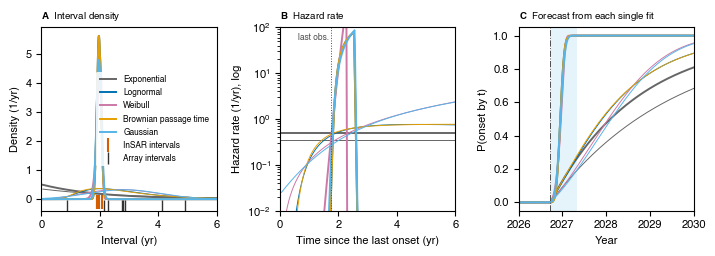

In [12]:
# [24]
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt
model_colours = {"exponential": "0.4", "lognormal": "#0072B2", "weibull": "#CC79A7", "bpt": "#E69F00", "gaussian": "#56B4E9"}   # Okabe-Ito, no green
model_names = {"exponential": "Exponential", "lognormal": "Lognormal", "weibull": "Weibull", "bpt": "Brownian passage time", "gaussian": "Gaussian"}
insar_colour = "#D55E00"               # Okabe-Ito vermillion: InSAR in every figure of this notebook
array_colour = "#0072B2"               # Okabe-Ito blue: the alignment array
combined_colour = "#CC79A7"            # Okabe-Ito reddish purple: the combined record
onset_line_colour = "#E69F00"          # Okabe-Ito orange: InSAR onset lines
wet_shade_colour = "#56B4E9"           # Okabe-Ito sky blue: the wet season
interval_axis = np.linspace(0.05, 6.0, 600)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.6))
for model in models:
    for cat, lw in (("A", 1.4), ("B", 0.7)):
        dist = single_fits[(cat, model)]
        axes[0].plot(interval_axis, dist.pdf(interval_axis), color=model_colours[model], lw=lw, label=model_names[model] if cat == "A" else None)
        hazard = dist.pdf(interval_axis) / np.clip(dist.sf(interval_axis), 1e-12, None)
        axes[1].plot(interval_axis, hazard, color=model_colours[model], lw=lw)
        axes[2].plot(grid, conditional_cdf(dist, last_onset_lo, time_since_last_yr), color=model_colours[model], lw=lw)
axes[0].plot(insar_intervals, np.full_like(insar_intervals, -0.1), "|", color=insar_colour, ms=10, mew=1.5, label="InSAR intervals")
axes[0].plot(array_intervals, np.full_like(array_intervals, -0.25), "|", color="0.2", ms=8, mew=1.0, label="Array intervals")
axes[0].set_xlim(0, 6)
axes[0].set_ylim(-0.4, None)
axes[0].set_xlabel("Interval (yr)")
axes[0].set_ylabel("Density (1/yr)")
utils.panel_title(axes[0], "A", "Interval density")
axes[0].legend(fontsize=6)
axes[1].axvline(time_since_last_yr, color="0.3", lw=0.7, ls=":")
axes[1].text(time_since_last_yr - 0.05, 0.97, "last obs.", transform=axes[1].get_xaxis_transform(), fontsize=6, color="0.3", va="top", ha="right")
axes[1].set_xlim(0, 6)
axes[1].set_yscale("log")
axes[1].set_ylim(0.01, 100)
axes[1].set_xlabel("Time since the last onset (yr)")
axes[1].set_ylabel("Hazard rate (1/yr), log")
utils.panel_title(axes[1], "B", "Hazard rate")
axes[2].axvspan(*decyear(pd.to_datetime(list(forecast_wet_season))), color=wet_shade_colour, alpha=0.15, lw=0)
axes[2].axvline(last_obs_day_yr, color="0.3", lw=0.7, ls="-.")
axes[2].set_xlim(2026.0, 2030.0)
axes[2].set_xlabel("Year")
axes[2].set_ylabel("P(onset by t)")
utils.panel_title(axes[2], "C", "Forecast from each single fit")
fig.tight_layout()
f_models = os.path.join(fig_dir, "qc11_renewal_models_single_fits.png")
fig.savefig(f_models, dpi=300)
fig.savefig(f_models.replace(".png", ".pdf"))
print("Saved figure to:", f_models)
plt.show()

## [25] The repeat intervals and the forecast: onsets drawn within their windows (Fig 3C, 3D and the registered window)

Now the real thing: for each catalogue, 400 draws of the onsets within their windows; their intervals give
THE interval statistics of the record (`interval_statistics`: mean and SD, ddof = 1, per draw, averaged;
COV = SD / mean; Fig 3C draws them; written to `recurrence_intervals.csv`), and the AICc of each model on
the median draw. Then for each model 400 more draws, each fitted and bootstrapped, conditioned on no event
through the last observation. The onset draws are kept: the InSAR clock of [30] reads them.

In [13]:
# [26]
rng = np.random.default_rng(seed)
t_last_window = (float(insar_events.onset_lo.iloc[-1]), float(insar_events.onset_hi.iloc[-1]))
forecast_rows = []
forecast_curves = {}
onset_draws = {}                  # catalogue -> (n_timing, n_events) onset draws of the interval statistics (the clock reads A_insar's)
interval_stats = {}               # catalogue -> interval_statistics(...): the ONE definition of mean, SD, COV
stats_lines = ["11 FORECAST", "", "REPEAT INTERVALS AND RENEWAL FORECAST",
               f"last event onset window {ymd(t_last_window[0])} to {ymd(t_last_window[1])}; reference date (last observation) {last_obs}; InSAR record end {data_end}; "
               f"{n_timing} timing draws x {n_boot} bootstrap refits; {wet_label} {forecast_wet_season[0]}..{forecast_wet_season[1]} ({wet_months_text}); "
               f"forecast grid {grid[0]:.0f} to {grid_end_label[2:]} (a quantile not reached on it is '{grid_end_label}')",
               "interval statistics: per onset draw the sample mean and SD (ddof = 1) of the intervals, averaged over the draws; "
               "COV = SD / mean; +/- = 1 SD of the intervals"]
interval_rows = []
for cat_name, (catalogue, drop_lp) in catalogues.items():
    # the onset draws, their intervals and the record's interval statistics; the AICc of each model on the median draw
    interval_draws = []
    draws_this = []
    for _ in range(n_timing):
        onsets = rng.uniform(catalogue.onset_lo.values, catalogue.onset_hi.values)
        draws_this.append(onsets)
        interval_draws.append(intervals_from(onsets, catalogue.src.values, drop_lp))
    onset_draws[cat_name] = np.array(draws_this)
    interval_stats[cat_name] = interval_statistics(interval_draws, len(catalogue))
    record = interval_stats[cat_name]
    draw_means = record["draw_means"]
    median_draw = interval_draws[int(np.argsort(draw_means)[len(draw_means) // 2])]
    aicc_by_model = {}
    for model in models:
        aicc_by_model[model] = aicc(model, median_draw)[0]
    best_model = min(aicc_by_model, key=aicc_by_model.get)
    aicc_text = []
    for model in models:
        aicc_text.append(f"{model} {aicc_by_model[model]:.1f}")
    lp_text = " (Loma Prieta-spanning interval dropped)" if drop_lp else ""
    stats_lines += [f"{cat_name} ({record_keys[cat_name]}): {record['n_events']} events, {record['n_intervals']} intervals" + lp_text,
                    f"  interval mean {record['mean_yr']:.2f} +/- {record['sd_yr']:.2f} yr (1 SD), COV {record['cov']:.2f}; "
                    f"each interval over the draws: {', '.join(f'{v:.2f}' for v in record['per_interval_mean'])} yr; AICc: " + ", ".join(aicc_text)]
    interval_rows.append(dict(catalog=cat_name, record=record_keys[cat_name], n_events=record["n_events"], n_intervals=record["n_intervals"],
                              mean_yr=record["mean_yr"], sd_yr=record["sd_yr"], cov=record["cov"], drop_loma_prieta=drop_lp,
                              intervals_yr=" ".join(f"{v:.4f}" for v in record["per_interval_mean"])))
    for model in models:
        cdf, model_mean, model_cov, n_clipped, n_degenerate = forecast(model, catalogue, drop_lp, t_last_window, last_obs_day_yr, rng)
        forecast_curves[(cat_name, model)] = cdf
        row = dict(catalog=cat_name, record=record_keys[cat_name], model=model, ref="last_obs", ref_date=last_obs,
                   n_intervals=record["n_intervals"], model_mean_yr=model_mean, model_cov=model_cov,
                   aicc=aicc_by_model[model], daicc=aicc_by_model[model] - aicc_by_model[best_model],
                   q05=quantile_label(cdf, 0.05), q50=quantile_label(cdf, 0.5), q95=quantile_label(cdf, 0.95),
                   p_wet_season=prob_between(cdf, *forecast_wet_season),
                   p_by_grid_end=float(cdf[-1]),
                   n_bootstrap_intervals_clipped=n_clipped, n_curves_zero_survival=n_degenerate)
        forecast_rows.append(row)
        model_cov_name = "alpha" if model == "bpt" else "sd/mean"
        stats_lines.append(f"    {model:<12} fitted mean {model_mean:.2f} yr, {model_cov_name} {model_cov:.3f} | next onset 5-50-95%: "
                           f"{row['q05']} {row['q50']} {row['q95']} | P({wet_label}) {row['p_wet_season']:.2f} "
                           f"| clipped intervals {n_clipped}, zero-survival curves {n_degenerate}")
forecasts = pd.DataFrame(forecast_rows)
interval_table = pd.DataFrame(interval_rows)
interval_table.to_csv(os.path.join(out_dir, "recurrence_intervals.csv"), index=False, float_format="%.4f")
# the records the text quotes have the interval counts the review lists (audit D section 6): a changed catalogue must be seen
expected_counts = {"A_insar": (5, 4), "B_aa_dense": (9, 8), "B_aa_dense_noLP": (9, 7), "C_merged": (14, 11)}
for cat_name, (n_events_expected, n_intervals_expected) in expected_counts.items():
    got = (interval_stats[cat_name]["n_events"], interval_stats[cat_name]["n_intervals"])
    assert got == (n_events_expected, n_intervals_expected), f"{cat_name}: {got} events/intervals, expected {(n_events_expected, n_intervals_expected)}"
# no quantile may fall before the conditioning date (the conditional cdf is zero up to it); the quantiles beyond the
# grid are listed (written '> <grid end>', with the probability the curve reaches by then)
beyond_grid = []
for quantile_column in ("q05", "q50", "q95"):
    on_grid = forecasts[quantile_column] != grid_end_label
    assert (pd.to_datetime(forecasts.loc[on_grid, quantile_column]) > pd.Timestamp(last_obs)).all(), \
        f"a forecast {quantile_column} falls on or before the last observation {last_obs}"
    for row in forecasts[~on_grid].itertuples():
        beyond_grid.append(f"{row.catalog} {row.model} {quantile_column} (P by grid end {row.p_by_grid_end:.3f})")
stats_lines.append(f"quantiles beyond the forecast grid ({grid_end_label}): " + (", ".join(beyond_grid) if beyond_grid else "none"))
forecasts.to_csv(os.path.join(out_dir, "recurrence_forecast_models.csv"), index=False, float_format="%.3f")
print("\n".join(stats_lines))

/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:2766: RuntimeWarning: overflow encountered in power
  return -sc.expm1(-pow(x, c))


11 FORECAST

REPEAT INTERVALS AND RENEWAL FORECAST
last event onset window 2024-12-26 to 2025-01-07; reference date (last observation) 2026-09-24; InSAR record end 2026-03-21; 400 timing draws x 5 bootstrap refits; WY2027 wet season 2026-10-01..2027-04-30 (Oct-Apr); forecast grid 2025 to 2039-01-01 (a quantile not reached on it is '> 2039-01-01')
interval statistics: per onset draw the sample mean and SD (ddof = 1) of the intervals, averaged over the draws; COV = SD / mean; +/- = 1 SD of the intervals
A_insar (insar): 5 events, 4 intervals
  interval mean 1.97 +/- 0.08 yr (1 SD), COV 0.04; each interval over the draws: 2.08, 1.92, 1.98, 1.90 yr; AICc: exponential 17.4, lognormal 6.1, weibull 6.6, bpt 6.1, gaussian 6.3
    exponential  fitted mean 1.97 yr, sd/mean 1.000 | next onset 5-50-95%: 2026-10-23 2027-11-23 2033-04-28 | P(WY2027 wet season) 0.30 | clipped intervals 200, zero-survival curves 0
    lognormal    fitted mean 1.97 yr, sd/mean 0.035 | next onset 5-50-95%: 2026-11-13 20

## [27] The Working Group aperiodicities, the uncertainty of the fitted alpha, the falsification dates

**WGCEP 1999 branches.** For each record, the BPT forecast of [26] with alpha FIXED at each of
`wg99_alpha_branches` (0.3, 0.5, 0.7; OFR 99-517 printed p16), only the mean fitted to each onset draw and
refitted in the bootstrap, each branch on its own generator started from `seed` (the same onset and bootstrap
draws for the three branches). The branches' conditional cdfs are mixed with `wg99_alpha_weights` (0.2, 0.6,
0.2: the report's three-way branch convention, App. C printed p31; the alpha weights themselves are not
printed); the mixture's P(wet season) under the alternative weightings is printed and its range registered, so
the insensitivity to the weights shows.

**The fitted alpha and its uncertainty (InSAR).** Four intervals constrain alpha only loosely: its 95 % CI from
the chi-square pivot of the inverse Gaussian (lambda * sum(1/x - 1/mean) ~ chi2(n - 1), on the intervals averaged
over the onset draws). The fitted-alpha forecast with alpha drawn from that pivot (`forecast_bpt_alpha_pivot`)
carries this uncertainty, which [26]'s parametric bootstrap cannot (its refits stay near the biased-low MLE).

**Falsification.** The fitted-alpha InSAR forecast of [26] is a near-deterministic clock: the dates by which its
conditional survival (the chance of no event yet, 1 - the conditional cdf) falls to `falsification_levels`
(5 % and 1 %). No event by then rejects that model at 95 % and 99 %. (The 5 % date is the forecast's 95 %
quantile, `11_insar_bpt_q95`.)

In [14]:
# [28]
wg99_rows = []
wg99_curves = {}                  # (catalogue, alpha or "mixture") -> mean conditional cdf
wg99_lines = ["", f"WORKING GROUP APERIODICITIES (WGCEP 1999, OFR 99-517 p16): BPT with alpha fixed at {wg99_alpha_branches}, "
              f"mixed with weights {wg99_alpha_weights} (App. C p31 three-way convention; the alpha weights are not printed in the report)"]
for cat_name, (catalogue, drop_lp) in catalogues.items():
    for alpha in wg99_alpha_branches:
        cdf, model_mean, model_cov, n_clipped, n_degenerate = forecast("bpt", catalogue, drop_lp, t_last_window, last_obs_day_yr,
                                                                       np.random.default_rng(seed), alpha_fixed=alpha)
        assert abs(model_cov - alpha) < 1e-6, f"{cat_name}: the fixed-alpha fits have sd/mean {model_cov:.4f}, not {alpha}"
        wg99_curves[(cat_name, alpha)] = cdf
        wg99_rows.append(dict(catalog=cat_name, record=record_keys[cat_name], branch=f"alpha {alpha:g}", alpha=alpha,
                              weight=wg99_alpha_weights[wg99_alpha_branches.index(alpha)],
                              q05=quantile_label(cdf, 0.05), q50=quantile_label(cdf, 0.5), q95=quantile_label(cdf, 0.95),
                              p_wet_season=prob_between(cdf, *forecast_wet_season), p_by_grid_end=float(cdf[-1]),
                              n_bootstrap_intervals_clipped=n_clipped, n_curves_zero_survival=n_degenerate))
    mixture = np.zeros_like(grid)
    for alpha, weight in zip(wg99_alpha_branches, wg99_alpha_weights):
        mixture += weight * wg99_curves[(cat_name, alpha)]
    wg99_curves[(cat_name, "mixture")] = mixture
    alternative_p = {}
    for weights_name, weights in wg99_alternative_weights.items():
        alternative_mixture = np.zeros_like(grid)
        for alpha, weight in zip(wg99_alpha_branches, weights):
            alternative_mixture += weight * wg99_curves[(cat_name, alpha)]
        alternative_p[weights_name] = prob_between(alternative_mixture, *forecast_wet_season)
    mixture_p = prob_between(mixture, *forecast_wet_season)
    all_weightings_p = [mixture_p] + list(alternative_p.values())
    wg99_rows.append(dict(catalog=cat_name, record=record_keys[cat_name], branch="WG99 mixture", alpha=np.nan, weight=1.0,
                          q05=quantile_label(mixture, 0.05), q50=quantile_label(mixture, 0.5), q95=quantile_label(mixture, 0.95),
                          p_wet_season=mixture_p, p_by_grid_end=float(mixture[-1]),
                          p_wet_weightings_min=min(all_weightings_p), p_wet_weightings_max=max(all_weightings_p)))
    branch_text = []
    for alpha in wg99_alpha_branches:
        branch_text.append(f"{alpha:g}: {prob_between(wg99_curves[(cat_name, alpha)], *forecast_wet_season):.2f}")
    wg99_lines.append(f"  {cat_name}: mixture 5-50-95% {wg99_rows[-1]['q05']} {wg99_rows[-1]['q50']} {wg99_rows[-1]['q95']}, "
                      f"P({wet_label}) {mixture_p:.3f} (other weightings: " +
                      ", ".join(f"{name} {value:.3f}" for name, value in alternative_p.items()) +
                      f"); single branches P({wet_label}) " + ", ".join(branch_text))

# the fitted alpha of the InSAR record: its 95 % CI (chi-square pivot on the intervals averaged over the onset draws)
insar_mean_intervals = interval_stats["A_insar"]["per_interval_mean"]
n_insar_intervals = insar_mean_intervals.size
pivot_sum = float(np.sum(1 / insar_mean_intervals - 1 / insar_mean_intervals.mean()))
insar_alpha_ci95 = (float(np.sqrt(insar_mean_intervals.mean() * pivot_sum / stats.chi2.ppf(0.975, n_insar_intervals - 1))),
                    float(np.sqrt(insar_mean_intervals.mean() * pivot_sum / stats.chi2.ppf(0.025, n_insar_intervals - 1))))
# the fitted-alpha forecast with alpha drawn from that pivot
pivot_cdf, pivot_alphas = forecast_bpt_alpha_pivot(insar_events, False, t_last_window, last_obs_day_yr, np.random.default_rng(seed))
wg99_curves[("A_insar", "alpha pivot")] = pivot_cdf
wg99_rows.append(dict(catalog="A_insar", record="insar", branch="fitted alpha, drawn from its chi2 pivot", alpha=float(np.median(pivot_alphas)),
                      weight=1.0, q05=quantile_label(pivot_cdf, 0.05), q50=quantile_label(pivot_cdf, 0.5), q95=quantile_label(pivot_cdf, 0.95),
                      p_wet_season=prob_between(pivot_cdf, *forecast_wet_season), p_by_grid_end=float(pivot_cdf[-1])))
insar_bpt_row = forecasts[(forecasts.catalog == "A_insar") & (forecasts.model == "bpt")].iloc[0]
wg99_lines.append(f"  InSAR fitted alpha (MLE, mean over the forecast draws) {insar_bpt_row.model_cov:.3f}; 95 % CI (chi2 pivot, n-1 = "
                  f"{n_insar_intervals - 1}) {insar_alpha_ci95[0]:.3f}-{insar_alpha_ci95[1]:.3f}; with alpha drawn from the pivot (median "
                  f"{np.median(pivot_alphas):.3f}, 95th pct {np.percentile(pivot_alphas, 95):.3f}): 5-50-95% {wg99_rows[-1]['q05']} "
                  f"{wg99_rows[-1]['q50']} {wg99_rows[-1]['q95']}, P({wet_label}) {wg99_rows[-1]['p_wet_season']:.3f} "
                  f"(fitted alpha alone: {insar_bpt_row.p_wet_season:.3f})")

# falsification: when the fitted-alpha InSAR model's conditional survival falls to each level
falsification_dates = {}
for level in falsification_levels:
    falsification_dates[level] = quantile_label(forecast_curves[("A_insar", "bpt")], 1 - level)
    assert falsification_dates[level] != grid_end_label, f"the InSAR BPT never reaches survival {level} on the grid"
pivot_falsification = {}
for level in falsification_levels:
    pivot_falsification[level] = quantile_label(pivot_cdf, 1 - level)
wg99_lines.append("  falsification (fitted-alpha InSAR BPT): no event by " +
                  ", ".join(f"{falsification_dates[level]} (survival {level:g})" for level in falsification_levels) +
                  " rejects it at " + ", ".join(f"{1 - level:.0%}" for level in falsification_levels) +
                  "; with alpha from its pivot the same levels fall on " + ", ".join(pivot_falsification[level] for level in falsification_levels))
wg99_table = pd.DataFrame(wg99_rows)
wg99_table.to_csv(os.path.join(out_dir, "recurrence_forecast_wg99.csv"), index=False, float_format="%.4f")
stats_lines += wg99_lines
print("\n".join(wg99_lines))


WORKING GROUP APERIODICITIES (WGCEP 1999, OFR 99-517 p16): BPT with alpha fixed at (0.3, 0.5, 0.7), mixed with weights (0.2, 0.6, 0.2) (App. C p31 three-way convention; the alpha weights are not printed in the report)
  A_insar: mixture 5-50-95% 2026-10-13 2027-05-14 2029-09-17, P(WY2027 wet season) 0.459 (other weightings: equal 0.467, 0.2/0.5/0.3 0.452); single branches P(WY2027 wet season) 0.3: 0.58, 0.5: 0.45, 0.7: 0.37
  B_aa_dense: mixture 5-50-95% 2026-11-04 2027-11-17 2031-02-23, P(WY2027 wet season) 0.268 (other weightings: equal 0.263, 0.2/0.5/0.3 0.266); single branches P(WY2027 wet season) 0.3: 0.25, 0.5: 0.27, 0.7: 0.26
  B_aa_dense_noLP: mixture 5-50-95% 2026-10-26 2027-09-07 2030-08-19, P(WY2027 wet season) 0.326 (other weightings: equal 0.325, 0.2/0.5/0.3 0.322); single branches P(WY2027 wet season) 0.3: 0.36, 0.5: 0.33, 0.7: 0.29
  C_merged: mixture 5-50-95% 2026-10-21 2027-07-27 2030-03-23, P(WY2027 wet season) 0.367 (other weightings: equal 0.370, 0.2/0.5/0.3 0.362)

## [29] The InSAR clock in closed form

The plain arithmetic the text quotes, on the SAME `n_timing` draws of the InSAR onsets as the interval
statistics of [26] (`onset_draws["A_insar"]`; until 2026-10-06 a second generator with the same seed made
identical draws): the mean and sd of the intervals, next = last + mean, and a t-based 95 % prediction
interval for a single new interval, mean +/- t(n-1) s sqrt(1 + 1/n). The registered numbers are the
averages over the draws; the spread of the next date over the draws is printed alongside. The mean and
sd are the interval statistics of [26] (asserted equal). The clock is not conditioned on the quiet time:
its dates before the last observation are listed, and are not a forecast window.

In [15]:
# [30]
def clock_prediction(intervals_yr, last_onset):
    """The plain clock from one set of intervals: (mean, sd, next = last + mean, 95 % prediction half-width
    t(n-1, 0.975) x sd x sqrt(1 + 1/n)), all in years."""
    n = len(intervals_yr)
    mean_yr = float(np.mean(intervals_yr))
    sd_yr = float(np.std(intervals_yr, ddof=1))
    half_width = float(stats.t.ppf(0.975, n - 1) * sd_yr * np.sqrt(1 + 1 / n))
    return mean_yr, sd_yr, last_onset + mean_yr, half_width


clock_draws = []
interval_sum = None
for onsets_this_draw in onset_draws["A_insar"]:
    onsets_drawn = np.sort(onsets_this_draw)
    intervals_drawn = np.diff(onsets_drawn)
    clock_draws.append(clock_prediction(intervals_drawn, onsets_drawn[-1]))
    interval_sum = intervals_drawn if interval_sum is None else interval_sum + intervals_drawn
clock_draws = np.array(clock_draws)
n_intervals = n_insar_events - 1
clock_intervals = interval_sum / n_timing                 # each interval, averaged over the draws (for the printout)
interval_mean_yr = float(clock_draws[:, 0].mean())
interval_sd_yr = float(clock_draws[:, 1].mean())
next_onset_yr = float(clock_draws[:, 2].mean())
half_width_yr = float(clock_draws[:, 3].mean())
next_spread_days = float(clock_draws[:, 2].std() * 365.25)
assert abs(interval_mean_yr - interval_stats["A_insar"]["mean_yr"]) < 1e-12 and abs(interval_sd_yr - interval_stats["A_insar"]["sd_yr"]) < 1e-12, \
    "the clock's mean / sd are not the interval statistics of [26]"
assert n_intervals == interval_stats["A_insar"]["n_intervals"]
sd_ci_days = (interval_sd_yr * np.sqrt((n_intervals - 1) / stats.chi2.ppf(.975, n_intervals - 1)) * 365.25,
              interval_sd_yr * np.sqrt((n_intervals - 1) / stats.chi2.ppf(.025, n_intervals - 1)) * 365.25)
clock_interval_text = []
for value in clock_intervals:
    clock_interval_text.append(f"{value:.2f}")
clock_lines = ["InSAR clock, closed form, averaged over " + f"{n_timing} uniform onset draws: intervals " + ", ".join(clock_interval_text) +
               f" yr; mean {interval_mean_yr:.3f} yr, sd {interval_sd_yr * 365.25:.0f} d (95% CI {sd_ci_days[0]:.0f}-{sd_ci_days[1]:.0f} d), "
               f"CoV {interval_sd_yr / interval_mean_yr:.3f}",
               f"  next = last + mean = {next_onset_yr:.3f} ({ymd(next_onset_yr)}; spread over the draws {next_spread_days:.0f} d sd); "
               f"+/-1 sd {ymd(next_onset_yr - interval_sd_yr)}..{ymd(next_onset_yr + interval_sd_yr)}; "
               f"95% prediction interval (t, n={n_intervals}) {ymd(next_onset_yr - half_width_yr)}..{ymd(next_onset_yr + half_width_yr)}"]
# the clock is not conditioned on the quiet time: say which of its dates already lie before the last observation
clock_dates = {"next": next_onset_yr, "-1 sd": next_onset_yr - interval_sd_yr, "+1 sd": next_onset_yr + interval_sd_yr,
               "PI95 lo": next_onset_yr - half_width_yr, "PI95 hi": next_onset_yr + half_width_yr}
clock_before = []
for name, value in clock_dates.items():
    if value <= last_obs_day_yr:
        clock_before.append(f"{name} {ymd(value)}")
clock_lines.append(f"  clock dates on or before the last observation {last_obs} (the clock is unconditional): " +
                   (", ".join(clock_before) if clock_before else "none"))
stats_lines += clock_lines
print("\n".join(clock_lines))

InSAR clock, closed form, averaged over 400 uniform onset draws: intervals 2.08, 1.92, 1.98, 1.90 yr; mean 1.971 yr, sd 29 d (95% CI 17-109 d), CoV 0.041
  next = last + mean = 2026.971 (2026-12-21; spread over the draws 4 d sd); +/-1 sd 2026-11-22..2027-01-20; 95% prediction interval (t, n=4) 2026-09-08..2027-04-04
  clock dates on or before the last observation 2026-09-24 (the clock is unconditional): PI95 lo 2026-09-08


## [31] Figure 3: the HRKT history, the onsets on the water year, the repeat intervals and the forecast

Left column on one time axis: A) the HRKT record with the bimonthly-era detections shaded, the
annual-survey years greyed, the InSAR stack tied to it and the InSAR onsets dashed, HRKT since 2015
as an inset (HGIL dropped, Dani 2026-10-01); B) the onset windows on the water year over the 7-day
rain (from 10_rain_seasonality). Right column: C) the repeat intervals of the three catalogues the
text quotes (the array and combined records leave out the interval spanning Loma Prieta): each
interval as a bar over its possible range (window to window, no point), the mean and SD of the
record marked and written, the ONE definition of [26] (`interval_statistics`; registered as
`11_<rec>_interval_mean_yr`, `_sd_yr`); D) the conditional probability of the next onset, BPT with the
fitted alpha, one line per catalogue, the 2026-27 wet season shaded (unchanged 2026-10-06: the Working
Group branches are not drawn). The inset of A ends at the data end (`data_end`).

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved Fig 3 to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-06/fig3_history_forecast_ntiming400_nboot5_issue2026-08-25.png
Fig 3C InSAR: 4 intervals, mean 1.971 yr, SD 0.080 yr (the interval statistics of [26])
Fig 3C A. Array: 7 intervals, mean 2.547 yr, SD 0.981 yr (the interval statistics of [26])
Fig 3C Combined: 11 intervals, mean 2.338 yr, SD 0.812 yr (the interval statistics of [26])


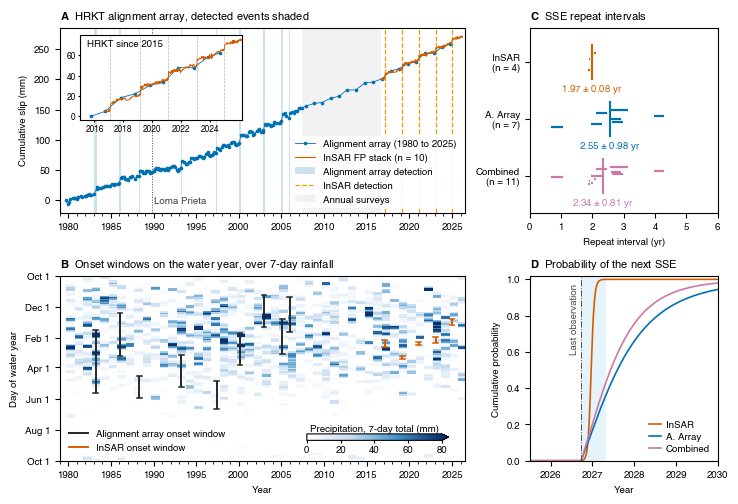

In [16]:
# [32]
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
shown = ["A_insar", "B_aa_dense_noLP", "C_merged"]       # the array without the Loma Prieta interval; B (with it) stays in the table
colours = {"A_insar": insar_colour, "B_aa_dense_noLP": array_colour, "C_merged": combined_colour}
labels = {"A_insar": "InSAR", "B_aa_dense_noLP": "A. Array", "C_merged": "Combined"}
label_pt = 7

# the left column's inputs, saved by 09 and 10
rain_panel = np.load(rain_panel_file)
windows = pd.read_csv(windows_file)
aa_stacks = pd.read_csv(aa_stacks_file)
hrkt = utils.load_aa(common_paths["aa_dir"], "HRKT")
hrkt_stack = aa_stacks[aa_stacks.code == "HRKT"]
x0 = float(rain_panel["x0"])
x1 = float(rain_panel["x1"])
dense_era_end = float(rain_panel["dense_era_end"])
# the catalogues drawn on the left are the ones the forecast fits: same onsets, in the same order
assert np.allclose(np.sort(windows.query("src == 'insar'").onset_lo), np.sort(catalogues["A_insar"][0].onset_lo), rtol=0, atol=1e-6)
assert np.allclose(np.sort(windows.query("src == 'aa_dense'").onset_lo), np.sort(aa_dense.onset_lo), rtol=0, atol=1e-6)


def onset_bar(ax, x, day_lo, day_hi, color, lw):
    """A vertical bar from day_lo to day_hi of the water year at x, wrapping across Oct 1 if needed."""
    if day_hi >= day_lo:
        segments = [(day_lo, day_hi)]
    else:
        segments = [(day_lo, 366), (1, day_hi)]
    for segment_lo, segment_hi in segments:
        ax.plot([x, x], [segment_lo, segment_hi], "-", color=color, lw=lw, solid_capstyle="butt", zorder=5)
    for y in (day_lo, day_hi):
        ax.plot([x - 0.28, x + 0.28], [y, y], "-", color=color, lw=lw * 0.8, zorder=5)


# full Science width (7.2 in = 18.3 cm); panels placed by hand (inches) so the columns align whatever the labels
fig_w = 7.2
fig_h = 5.05


def place(x, y, w, h):
    """An axes at (x, y) with width w and height h, all in inches on the figure."""
    return fig.add_axes([x / fig_w, y / fig_h, w / fig_w, h / fig_h])


fig = plt.figure(figsize=(fig_w, fig_h))
# all four panels the same height (Dani 2026-10-01); the row gap leaves room for C's x label above D's title
left_x = 0.50
left_w = 4.05
right_x = 5.20
right_w = 1.88
panel_h = 1.85
row_y = (2.90, 0.42)
ax_a = place(left_x, row_y[0], left_w, panel_h)
ax_b = place(left_x, row_y[1], left_w, panel_h)
ax_c = place(right_x, row_y[0], right_w, panel_h)
ax_d = place(right_x, row_y[1], right_w, panel_h)
for ax in (ax_a, ax_b, ax_c, ax_d):
    ax.tick_params(labelsize=label_pt)

# A) the HRKT record
ax = ax_a
ax.plot(hrkt.year, hrkt.cum_mm, "o", ms=1.6, color=array_colour, lw=0.6, ls="-", zorder=3,
        label=f"Alignment array ({hrkt.year.min():.0f} to {hrkt.year.max():.0f})")
ax.plot(hrkt_stack.date, hrkt_stack.slip_mm, "-", lw=0.8, color=insar_colour, zorder=5,
        label=f"InSAR FP stack (n = {int(hrkt_stack.n_crossings.iloc[0])})")       # shifted onto the array datum (caption)
for i, window in enumerate(windows.query("src == 'aa_dense'").itertuples()):
    ax.axvspan(window.onset_lo, window.onset_hi, color=array_colour, alpha=0.20, lw=0, zorder=1,
               label="Alignment array detection" if i == 0 else None)
ax.axvspan(dense_era_end, float(rain_panel["insar_start"]), color="0.5", alpha=0.10, lw=0, zorder=0, label="Annual surveys")
for i, step_epoch in enumerate(windows.query("src == 'insar'").onset_lo):       # at each step epoch (the window is too narrow to see)
    ax.axvline(step_epoch, color=onset_line_colour, lw=0.9, ls="--", zorder=2, label="InSAR detection" if i == 0 else None)
ax.axvline(float(rain_panel["loma_prieta"]), color="0.25", lw=0.7, ls=":", zorder=2)
ax.text(float(rain_panel["loma_prieta"]) + 0.3, 0.04, "Loma Prieta", transform=ax.get_xaxis_transform(), fontsize=label_pt, color="0.25",
        ha="left", va="bottom", bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))     # between the array curve and the x axis
ax.set_ylabel("Cumulative slip (mm)", fontsize=label_pt)
handles, leg_labels = ax.get_legend_handles_labels()
legend_order = []                                       # the grey "Annual surveys" last
for i, leg_label in enumerate(leg_labels):
    if leg_label != "Annual surveys":
        legend_order.append(i)
legend_order.append(leg_labels.index("Annual surveys"))
ordered_handles = []
ordered_labels = []
for i in legend_order:
    ordered_handles.append(handles[i])
    ordered_labels.append(leg_labels[i])
ax.legend(ordered_handles, ordered_labels, fontsize=label_pt, loc="lower right", frameon=True,
          facecolor="white", edgecolor="none", framealpha=0.9)
ax.set_title(r"$\bf{A}$  HRKT alignment array, detected events shaded", loc="left", fontsize=8)
ax.set_xlim(x0, x1)                                  # year labels but no "Year" title: it fills the row gap (Dani 2026-10-01)
# HRKT since 2015 as one larger inset (Dani 2026-10-01: HGIL dropped), zeroed at its first survey
zoom_t0 = 2015.0
recent = hrkt[hrkt.year >= zoom_t0]
zero = float(recent.cum_mm.iloc[0])
inset = ax.inset_axes([0.05, 0.50, 0.40, 0.46])      # top left, above the array curve, which reaches this height only after 2010
inset.plot(recent.year, recent.cum_mm - zero, "o", ms=1.6, color=array_colour, lw=0.6, ls="-")
inset.plot(hrkt_stack.date, hrkt_stack.slip_mm - zero, "-", lw=0.7, color=insar_colour)
for step_epoch in windows.query("src == 'insar'").onset_lo:
    inset.axvline(step_epoch, color="0.7", lw=0.5, ls="--", zorder=0)
inset.set_xlim(zoom_t0, data_end_yr)                 # to the end of the InSAR record (until 2026-10-06 a typed 2026.2)
inset.set_xticks([2016, 2018, 2020, 2022, 2024])
inset.tick_params(labelsize=6, length=1.5, pad=1.5)
inset.text(0.04, 0.95, "HRKT since 2015", transform=inset.transAxes, fontsize=label_pt, va="top")

# B) the onset windows on the water year over the 7-day rain
ax = ax_b
rain_cmap = LinearSegmentedColormap.from_list("rain", list(rain_panel["rain_colours"]))
density_max = float(rain_panel["density_max"])
density_days = int(rain_panel["density_days"])
mesh = ax.pcolormesh(rain_panel["x_edges"], np.arange(-0.5, 367.5), rain_panel["rain_grid"], cmap=rain_cmap, vmin=0, vmax=density_max,
                     shading="flat", rasterized=True, zorder=0)
for window in windows.itertuples():
    bar_colour = "0.15" if window.src == "aa_dense" else insar_colour
    onset_bar(ax, window.onset_mid, window.dowy_lo, window.dowy_hi, bar_colour, 1.4)
ax.set_ylim(366, 1)
ax.set_yticks([1, 62, 124, 182, 244, 305, 366])
ax.set_yticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_xlabel("Year", fontsize=label_pt)
ax.set_ylabel("Day of water year", fontsize=label_pt)
ax.add_patch(plt.Rectangle((0.575, 0.04), 0.415, 0.24, transform=ax.transAxes, facecolor="white", edgecolor="none", alpha=0.85, zorder=4))
cax = ax.inset_axes([0.61, 0.11, 0.35, 0.035])
cb = fig.colorbar(mesh, cax=cax, orientation="horizontal", extend="max")
cb.set_label(f"Precipitation, {density_days}-day total (mm)", fontsize=label_pt, labelpad=2)
cb.ax.xaxis.set_label_position("top")
cb.ax.tick_params(labelsize=label_pt, length=2, pad=1.5)
ax.legend(handles=[Line2D([], [], color="0.15", lw=1.4, label="Alignment array onset window"),
                   Line2D([], [], color=insar_colour, lw=1.4, label="InSAR onset window")], fontsize=label_pt, loc="lower left",
          frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
ax.set_title(r"$\bf{B}$  Onset windows on the water year, over 7-day rainfall", loc="left", fontsize=8)
ax.set_xlim(x0, x1)
for ax in (ax_a, ax_b):                              # Roland: annual ticks, years labelled every 5 (B; A shares the axis)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.xaxis.set_minor_locator(MultipleLocator(1))

# C) the repeat intervals of each catalogue: each interval as a bar over its possible range (from the end of the earlier
# window to the start of the later one, up to the start of the earlier to the end of the later), the mean of the onset
# draws marked, mean and sd written under it
ax = ax_c
tick_labels = []
fig3c_numbers = {}                 # catalogue -> (mean, sd, number of intervals): interval_stats of [26], printed
for j, cat_name in enumerate(shown):
    catalogue, drop_lp = catalogues[cat_name]
    catalogue = catalogue.sort_values("onset_mid").reset_index(drop=True)
    keep = interval_mask(catalogue.onset_mid.values, catalogue.src.values, drop_lp)     # which pairs form an interval (order and Loma Prieta side)
    shortest = (catalogue.onset_lo.values[1:] - catalogue.onset_hi.values[:-1])[keep]
    longest = (catalogue.onset_hi.values[1:] - catalogue.onset_lo.values[:-1])[keep]
    rows_y = j + np.linspace(-0.15, 0.15, len(shortest))
    ax.hlines(rows_y, shortest, longest, color=colours[cat_name], lw=1.6)
    mean_yr = interval_stats[cat_name]["mean_yr"]
    sd_yr = interval_stats[cat_name]["sd_yr"]
    assert interval_stats[cat_name]["n_intervals"] == len(shortest), f"{cat_name}: Fig 3C draws {len(shortest)} intervals, [26] has another count"
    fig3c_numbers[cat_name] = (mean_yr, sd_yr, len(shortest))
    ax.plot([mean_yr, mean_yr], [j - 0.3, j + 0.3], "-", color=colours[cat_name], lw=1.5)
    ax.text(mean_yr, j + 0.36, f"{mean_yr:.2f} $\\pm$ {sd_yr:.2f} yr", ha="center", va="top", fontsize=7, color=colours[cat_name])
    tick_labels.append(f"{labels[cat_name]}\n(n = {len(shortest)})")      # the spans are read from A (Dani 2026-10-01)
ax.set_yticks(range(len(shown)))
ax.set_yticklabels(tick_labels, fontsize=label_pt, linespacing=1.1)
ax.set_ylim(len(shown) - 0.35, -0.6)          # inverted: first catalogue on top; room under the last bar for its number
ax.set_xlim(0, 6)
ax.set_xlabel("Repeat interval (yr)", fontsize=label_pt)
ax.set_title(r"$\bf{C}$  SSE repeat intervals", loc="left", fontsize=8)

# D) the conditional forecast, BPT, one line per catalogue; the wet season shaded, the last observation marked
ax = ax_d
wet_years = decyear(pd.to_datetime(list(forecast_wet_season)))
ax.axvspan(wet_years[0], wet_years[1], color=wet_shade_colour, alpha=0.15, lw=0)
for cat_name in shown:
    ax.plot(grid, forecast_curves[(cat_name, "bpt")], "-", color=colours[cat_name], lw=1.2, label=labels[cat_name])
ax.axvline(last_obs_day_yr, color="0.3", lw=0.7, ls="-.")
ax.text(last_obs_day_yr - 0.06, 0.98, "Last observation", fontsize=label_pt, color="0.3", va="top", ha="right", rotation=90)   # left of the line: the InSAR curve rises just right of it
ax.set_xlim(2025.5, 2030.0)
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Year", fontsize=label_pt)
ax.set_ylabel("Cumulative probability", fontsize=label_pt)
ax.set_title(r"$\bf{D}$  Probability of the next SSE", loc="left", fontsize=8)
ax.legend(fontsize=label_pt, loc="lower right", handlelength=1.2, handletextpad=0.5, borderpad=0.3, labelspacing=0.3,
          frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
f_fig3 = os.path.join(fig_dir, f"fig3_history_forecast_ntiming{n_timing}_nboot{n_boot}_issue{forecast_issue_date}.png")
fig.savefig(f_fig3, dpi=600)
fig.savefig(f_fig3.replace(".png", ".pdf"))
print("Saved Fig 3 to:", f_fig3)
for cat_name, (mean_yr, sd_yr, n_shown) in fig3c_numbers.items():
    print(f"Fig 3C {labels[cat_name]}: {n_shown} intervals, mean {mean_yr:.3f} yr, SD {sd_yr:.3f} yr (the interval statistics of [26])")
    stats_lines.append(f"Fig 3C {cat_name}: {n_shown} intervals, mean {mean_yr:.3f} yr, SD {sd_yr:.3f} yr (the interval statistics of [26])")
plt.show()

## [33] The prediction statement

Built from the numbers above in a fixed template, so the statement the paper
makes is generated, not typed. TIME WINDOW part (3), the calendar window of the onsets, and the
Fremont gauge's last day are 10_rain_seasonality's (`rain_conditioning_summary.csv`). LOCATION is 04's `section_lengths.csv`: the fault length hosting the
events (`tulepond_creep_length`) and the peak slip zone (`tulepond_band90`). MAGNITUDE is the paper's
step sizes, 04's 90 % band stack (`04_band90_step_<yr>_mm` with their 95 % CIs), read back from the
registry rows of 04's latest run; that run must be newer than `section_lengths.csv` and must have
registered the same onset windows as `creep_events.csv` (both asserted), so the statement cannot mix
two runs of 04. These are 04's numbers: nothing here is registered again.

In [17]:
# [34]
# LOCATION: 04's measured extents
section_lengths = pd.read_csv(section_lengths_file).set_index("name")
creep_length = section_lengths.loc["tulepond_creep_length"]
peak_zone = section_lengths.loc[f"tulepond_{magnitude_band}"]
# MAGNITUDE: the band-stack steps of 04's latest run, from the registry
registry_rows = pd.read_csv(common_paths["registry_csv"], dtype=str)
rows_04 = registry_rows[registry_rows.notebook == "04_event_detection"]
assert len(rows_04), "the registry has no rows of 04_event_detection"
last_run_04 = rows_04.sort_values("timestamp").run_id.iloc[-1]
rows_04 = rows_04[rows_04.run_id == last_run_04].set_index("key")
run_04_time = pd.Timestamp(rows_04.timestamp.min())          # the registry stamps local time to the second
section_lengths_time = pd.Timestamp.fromtimestamp(np.floor(os.path.getmtime(section_lengths_file)))     # local time, as the registry
assert run_04_time >= section_lengths_time - pd.Timedelta(seconds=1), \
    f"04's latest registry run ({run_04_time}) is older than {section_lengths_file}: 04 stopped before registering; rerun it"
event_labels = []
for onset_lo, onset_hi in zip(insar_events.onset_lo, insar_events.onset_hi):
    label = f"{int(onset_lo)}"                     # 04's key label: the year of the step epoch
    event_labels.append(label)
    assert np.isclose(float(rows_04.loc[f"04_onset_lo_{label}", "value"]), onset_lo, rtol=0, atol=1e-4) and \
        np.isclose(float(rows_04.loc[f"04_onset_hi_{label}", "value"]), onset_hi, rtol=0, atol=1e-4), \
        f"04's registered {label} window is not the one in {events_file}"
band_steps = []
band_ci_lo = []
band_ci_hi = []
for label in event_labels:
    band_steps.append(float(rows_04.loc[f"04_{magnitude_band}_step_{label}_mm", "value"]))
    band_ci_lo.append(float(rows_04.loc[f"04_{magnitude_band}_step_{label}_ci_lo", "value"]))
    band_ci_hi.append(float(rows_04.loc[f"04_{magnitude_band}_step_{label}_ci_hi", "value"]))
band_steps = np.array(band_steps)
assert np.isclose(band_steps.mean(), float(rows_04.loc[f"04_{magnitude_band}_steps_mean_mm", "value"]), rtol=0, atol=1e-6)
assert int(float(rows_04.loc[f"04_{magnitude_band}_n_crossings", "value"])) == int(peak_zone.n)
print(f"04 run {last_run_04} ({run_04_time}): {magnitude_band} steps {np.round(band_steps, 2).tolist()} mm, "
      f"95% CIs {min(band_ci_lo):.2f}-{max(band_ci_hi):.2f} mm")

insar_forecast = forecasts[forecasts.catalog == "A_insar"].set_index("model")
array_forecast = forecasts[forecasts.catalog == "B_aa_dense_noLP"].set_index("model")
array_lp_forecast = forecasts[forecasts.catalog == "B_aa_dense"].set_index("model")
merged_forecast = forecasts[forecasts.catalog == "C_merged"].set_index("model")
wg99_mixture = wg99_table[wg99_table.branch == "WG99 mixture"].set_index("catalog")
insar_pivot_row = wg99_table[wg99_table.branch.str.startswith("fitted alpha")].iloc[0]
insar_window_days = (insar_events.onset_hi - insar_events.onset_lo) * 365.25
array_first_year = int(np.floor(aa_dense.onset_lo.min()))


def wg99_text(cat_name):
    """The WG99-branch mixture of one record: its P(wet season), the range over the weightings, and the single
    branches' P, as one phrase."""
    mixture_row = wg99_mixture.loc[cat_name]
    branch_p = []
    for alpha in wg99_alpha_branches:
        branch_p.append(f"{prob_between(wg99_curves[(cat_name, alpha)], *forecast_wet_season):.2f}")
    return (f"with the Working Group aperiodicities (alpha {', '.join(f'{a:g}' for a in wg99_alpha_branches)}, weights "
            f"{', '.join(f'{w:g}' for w in wg99_alpha_weights)}; WGCEP 1999 p16) P({wet_label}) = {mixture_row.p_wet_season:.2f} "
            f"({mixture_row.p_wet_weightings_min:.2f}-{mixture_row.p_wet_weightings_max:.2f} for the other weightings; single branches "
            f"{' / '.join(branch_p)}), 5-95% {mixture_row.q05} .. {mixture_row.q95}")


# the tightest rule A / B lag spreads (10) beside the calendar spread of the onsets: printed side by side, no verdict
# (they differ by days, within the one-day resolution of a rain day)
rules_text = (f"      tightest rainfall rules (10_rain_seasonality): lag spread A {rain_value('ruleA_best_spread_d'):.0f} d, "
              f"B {rain_value('ruleB_best_spread_d'):.0f} d, against the calendar spread of the onsets {rain_value('calendar_spread_d'):.0f} d")
statement_lines = [
    "TULE POND CREEP-EVENT PREDICTION STATEMENT (generated by notebook 11_forecast)",
    f"first written {forecast_issue_date}; conditioned on no event through the last observation, {last_obs} "
    f"(descending CSLC + Dolphin extension check, extension_2026-09/RESULT.md); "
    f"data: OPERA DISP-S1 to {data_end} (the end of the paper's InSAR record), HRKT array events to {aa_dense.onset_hi.max():.2f} (bimonthly surveys to {dense_era_end:.2f}), "
    f"Fremont GHCN gauge to {rain_summary.loc['fremont_last_valid_day', 'value']} (10_rain_seasonality)",
    f"the renewal-model windows below run from the last observation; nothing is claimed for the months after {last_obs}", "",
    f"LOCATION  Hayward fault, Tule Pond section: the events slip {creep_length.km_lo:.1f}-{creep_length.km_hi:.1f} km from Point Pinole "
    f"({creep_length.km_hi - creep_length.km_lo:.1f} km of fault, {creep_length.lat_lo:.3f}-{creep_length.lat_hi:.3f} N); peak slip zone "
    f"({magnitude_band_pct} % of the peak event fraction) {peak_zone.km_lo:.1f}-{peak_zone.km_hi:.1f} km "
    f"({peak_zone.km_hi - peak_zone.km_lo:.1f} km, {peak_zone.lat_lo:.3f}-{peak_zone.lat_hi:.3f} N)",
    f"MAGNITUDE surface slip {band_steps.mean():.1f} mm on average, {band_steps.min():.1f}-{band_steps.max():.1f} mm per event, on the "
    f"{magnitude_band_pct} % band stack ({int(peak_zone.n)} crossings; {n_insar_events} InSAR events; 95% CIs {min(band_ci_lo):.1f}-{max(band_ci_hi):.1f} mm), "
    f"within one {insar_window_days.min():.0f}-{insar_window_days.max():.0f} d acquisition interval", "",
    "TIME WINDOW",
    f"  (1) InSAR record ({n_intervals} intervals, {interval_stats['A_insar']['n_events']} events): repeat interval {interval_mean_yr:.2f} +/- "
    f"{interval_sd_yr:.2f} yr (1 SD, {interval_sd_yr * 365.25:.0f} d), COV {interval_stats['A_insar']['cov']:.2f}, over {n_timing} onset draws",
    f"      clock: next = last + mean = {ymd(next_onset_yr)}; +/-1 sd {ymd(next_onset_yr - interval_sd_yr)}..{ymd(next_onset_yr + interval_sd_yr)}; "
    f"95% prediction interval (t, n={n_intervals}) {ymd(next_onset_yr - half_width_yr)}..{ymd(next_onset_yr + half_width_yr)} (unconditional)",
    f"      BPT with the alpha fitted to these intervals ({insar_forecast.loc['bpt', 'model_cov']:.3f}, 95 % CI {insar_alpha_ci95[0]:.2f}-{insar_alpha_ci95[1]:.2f}; "
    f"a statement conditional on the 2017-2025 regularity persisting): 5-95% {insar_forecast.loc['bpt', 'q05']} .. {insar_forecast.loc['bpt', 'q95']}, "
    f"median {insar_forecast.loc['bpt', 'q50']}; P({wet_label}, {wet_months_text}) = {insar_forecast.loc['bpt', 'p_wet_season']:.2f}; "
    f"with alpha drawn from its uncertainty {insar_pivot_row.p_wet_season:.2f}",
    f"      falsification: under that model the chance of no event falls to " +
    " and ".join(f"{level:.0%} by {falsification_dates[level]}" for level in falsification_levels) +
    f": no event by then rejects it at " + " / ".join(f"{1 - level:.0%}" for level in falsification_levels),
    f"      {wg99_text('A_insar')}",
    f"  (2) HRKT bimonthly-era record ({array_first_year}-{dense_era_end:.0f}), Loma Prieta interval dropped "
    f"({interval_stats['B_aa_dense_noLP']['n_intervals']} intervals, {interval_stats['B_aa_dense_noLP']['mean_yr']:.2f} +/- "
    f"{interval_stats['B_aa_dense_noLP']['sd_yr']:.2f} yr, COV {interval_stats['B_aa_dense_noLP']['cov']:.2f}): BPT (fitted alpha "
    f"{array_forecast.loc['bpt', 'model_cov']:.2f}) 5-95% {array_forecast.loc['bpt', 'q05']} .. {array_forecast.loc['bpt', 'q95']}, "
    f"median {array_forecast.loc['bpt', 'q50']}; P({wet_label}) = {array_forecast.loc['bpt', 'p_wet_season']:.2f}; {wg99_text('B_aa_dense_noLP')}",
    f"      with the Loma Prieta interval (as WGCEP 1999's parallel no-interaction run, p17; "
    f"{interval_stats['B_aa_dense']['n_intervals']} intervals, {interval_stats['B_aa_dense']['mean_yr']:.2f} +/- {interval_stats['B_aa_dense']['sd_yr']:.2f} yr, "
    f"COV {interval_stats['B_aa_dense']['cov']:.2f}): BPT P({wet_label}) = {array_lp_forecast.loc['bpt', 'p_wet_season']:.2f}; {wg99_text('B_aa_dense')}",
    f"      merged ({interval_stats['C_merged']['n_intervals']} intervals, {interval_stats['C_merged']['mean_yr']:.2f} +/- "
    f"{interval_stats['C_merged']['sd_yr']:.2f} yr, COV {interval_stats['C_merged']['cov']:.2f}): BPT 5-95% {merged_forecast.loc['bpt', 'q05']} .. "
    f"{merged_forecast.loc['bpt', 'q95']}, median {merged_forecast.loc['bpt', 'q50']}; P({wet_label}) = {merged_forecast.loc['bpt', 'p_wet_season']:.2f}; "
    f"{wg99_text('C_merged')}; Poisson null (the merged record's exponential, mean interval {interval_stats['C_merged']['mean_yr']:.2f} yr) "
    f"{merged_forecast.loc['exponential', 'p_wet_season']:.2f}",
    f"      (a quantile written '{grid_end_label}' is beyond the forecast grid: the curve has not reached it there)",
    f"  (3) all {int(rain_value('n_insar_onsets'))} InSAR onset windows fell {int(rain_value('onset_dowy_min'))}-{int(rain_value('onset_dowy_max'))} d into the water year "
    f"({rain_summary.loc['onset_earliest', 'value']}-{rain_summary.loc['onset_latest', 'value']}), after {rain_value('cum_at_onset_min_mm'):.0f}-"
    f"{rain_value('cum_at_onset_max_mm'):.0f} mm of WY rain ({rain_value('frac_at_onset_min'):.0%}-{rain_value('frac_at_onset_max'):.0%} of the WY total), "
    f"in years spanning P{rain_value('wy_percentile_min'):.0f}-P{rain_value('wy_percentile_max'):.0f} of the "
    f"{int(rain_value('wy_first'))}-{int(rain_value('wy_last'))} WY-total distribution (10_rain_seasonality)",
    f"      a {int(rain_value('rain_total_days'))}-day rain total of at least Z mm within X days before the onset (Fremont gauge, the "
    f"{int(rain_value('n_insar_onsets'))} InSAR onsets, {int(rain_value('rain_sweep_n_settings'))} settings of Z and X): the best, "
    f"{rain_value('rain_sweep_best_Z_mm'):.0f} mm within {rain_value('rain_sweep_best_X_d'):.0f} d, gives {rain_value('rain_sweep_best_hits'):.2f} of "
    f"{int(rain_value('n_insar_onsets'))} onsets against {rain_value('rain_sweep_best_null_hits'):.2f} for a random day of the same season in the same "
    f"water year, p = {rain_value('rain_sweep_best_p'):.3f}; p = {rain_value('rain_sweep_p_search_paid'):.3f} once all "
    f"{int(rain_value('rain_sweep_n_settings'))} settings are paid for",
    rules_text]
with open(os.path.join(out_dir, "prediction_statement.txt"), "w") as fh:
    fh.write("\n".join(statement_lines) + "\n")
print("\n".join(statement_lines))

04 run a270b6d7 (2026-10-06 13:11:21): band90 steps [10.69, 10.47, 11.25, 11.73, 7.74] mm, 95% CIs 6.45-13.14 mm
TULE POND CREEP-EVENT PREDICTION STATEMENT (generated by notebook 11_forecast)
first written 2026-08-25; conditioned on no event through the last observation, 2026-09-24 (descending CSLC + Dolphin extension check, extension_2026-09/RESULT.md); data: OPERA DISP-S1 to 2026-03-21 (the end of the paper's InSAR record), HRKT array events to 2006.06 (bimonthly surveys to 2007.44), Fremont GHCN gauge to 2026-08-21 (10_rain_seasonality)
the renewal-model windows below run from the last observation; nothing is claimed for the months after 2026-09-24

LOCATION  Hayward fault, Tule Pond section: the events slip 56.3-62.2 km from Point Pinole (5.9 km of fault, 37.535-37.580 N); peak slip zone (90 % of the peak event fraction) 58.2-59.8 km (1.6 km, 37.552-37.565 N)
MAGNITUDE surface slip 10.4 mm on average, 7.7-11.7 mm per event, on the 90 % band stack (17 crossings; 5 InSAR events; 95% 

## [35] Registry: the stats sidecar `11_forecast_stats.txt` (with the prediction statement) and the `11_*` numbers

Per record `<rec>` (`insar`, `aa_dense_nolp`, `aa_dense_withlp`, `merged`): the interval statistics of [26]
(`_interval_mean_yr`, `_interval_sd_yr`, `_interval_cov`, `_n_intervals`, `_n_events`); per model the
5-50-95 % dates, P(wet season) and dAICc; the fitted BPT aperiodicity (`_bpt_alpha`); the Working Group
mixture (`_bpt_wg99_q05/q50/q95/p_wet_wy<N>`, its range over the weightings `_wmin`/`_wmax`) and each branch's
P(wet season) (`_bpt_alpha03_p_wet_wy<N>` etc.). For the InSAR record also each interval (`11_insar_interval_<y1>_<y2>_yr`,
averaged over the onset draws; labels = the years of 04's step epochs), its SD in days with its 95 % CI, the
alpha CI and the alpha-pivot forecast, the falsification dates, and the clock.

In [18]:
# [36]
sidecar = REG.sidecar("11_forecast", stats_lines + ["", *statement_lines])
REG.register("11_issue_date", forecast_issue_date, "date", 0, where="P10, M9", cell="constants", sidecar=sidecar)
REG.register("11_data_end", data_end, "date", 0, where="P10, M9", cell="load", sidecar=sidecar)
REG.register("11_last_obs_date", last_obs, "date", 0, where="P10, M9", cell="load", sidecar=sidecar)
# the interval statistics: ONE definition ([26]), every record
for cat_name, key in record_keys.items():
    record = interval_stats[cat_name]
    REG.register(f"11_{key}_interval_mean_yr", record["mean_yr"], "yr", 2, where="P10, Fig3", cell="intervals", sidecar=sidecar)
    REG.register(f"11_{key}_interval_sd_yr", record["sd_yr"], "yr", 2, where="P10, Fig3", cell="intervals", sidecar=sidecar)
    REG.register(f"11_{key}_interval_cov", record["cov"], "1", 2, where="P10", cell="intervals", sidecar=sidecar)
    REG.register(f"11_{key}_n_intervals", record["n_intervals"], "count", 0, where="P10, Fig3", cell="intervals", sidecar=sidecar)
    REG.register(f"11_{key}_n_events", record["n_events"], "count", 0, where="P10, Fig3", cell="intervals", sidecar=sidecar)
# the InSAR intervals one by one (averaged over the onset draws), labelled by the years of 04's step epochs (onset_lo)
insar_years = []
for onset_lo in insar_events.onset_lo:
    insar_years.append(f"{int(onset_lo)}")
for k, value in enumerate(interval_stats["A_insar"]["per_interval_mean"]):
    REG.register(f"11_insar_interval_{insar_years[k]}_{insar_years[k + 1]}_yr", value, "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("11_insar_interval_sd_d", interval_sd_yr * 365.25, "d", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("11_insar_interval_sd_ci_lo_d", sd_ci_days[0], "d", 0, where="M9", cell="clock", sidecar=sidecar)
REG.register("11_insar_interval_sd_ci_hi_d", sd_ci_days[1], "d", 0, where="M9", cell="clock", sidecar=sidecar)
REG.register("11_next_clock_date", ymd(next_onset_yr), "date", 0, where="P10, Fig3", cell="clock", sidecar=sidecar)
REG.register("11_next_1sd_lo", ymd(next_onset_yr - interval_sd_yr), "date", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("11_next_1sd_hi", ymd(next_onset_yr + interval_sd_yr), "date", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("11_pi95_lo", ymd(next_onset_yr - half_width_yr), "date", 0, where="P10, Fig3", cell="clock", sidecar=sidecar)
REG.register("11_pi95_hi", ymd(next_onset_yr + half_width_yr), "date", 0, where="P10, Fig3", cell="clock", sidecar=sidecar)
# the renewal forecasts (fitted parameters) and the BPT aperiodicity
for cat_name, key in record_keys.items():
    issue = forecasts[forecasts.catalog == cat_name].set_index("model")
    for model in ("bpt", "lognormal", "weibull", "exponential"):
        REG.register(f"11_{key}_{model}_q05", issue.loc[model, "q05"], "date", 0, where="P10, Fig3", cell="forecast", sidecar=sidecar)
        REG.register(f"11_{key}_{model}_q50", issue.loc[model, "q50"], "date", 0, where="P10, Fig3", cell="forecast", sidecar=sidecar)
        REG.register(f"11_{key}_{model}_q95", issue.loc[model, "q95"], "date", 0, where="P10, Fig3", cell="forecast", sidecar=sidecar)
        REG.register(f"11_{key}_{model}_p_wet_wy{forecast_wy}", issue.loc[model, "p_wet_season"], "1", 2, where="P10, Fig3", cell="forecast", sidecar=sidecar)
        REG.register(f"11_{key}_{model}_daicc", issue.loc[model, "daicc"], "1", 2, where="M9", cell="forecast", sidecar=sidecar)
    REG.register(f"11_{key}_bpt_alpha", float(issue.loc["bpt", "model_cov"]), "1", 3, where="P10, M9", cell="forecast", sidecar=sidecar)
# the Working Group aperiodicities: the mixture and each branch
for cat_name, key in record_keys.items():
    mixture_row = wg99_mixture.loc[cat_name]
    REG.register(f"11_{key}_bpt_wg99_q05", mixture_row.q05, "date", 0, where="P10, M9", cell="wg99", sidecar=sidecar)
    REG.register(f"11_{key}_bpt_wg99_q50", mixture_row.q50, "date", 0, where="P10, M9", cell="wg99", sidecar=sidecar)
    REG.register(f"11_{key}_bpt_wg99_q95", mixture_row.q95, "date", 0, where="P10, M9", cell="wg99", sidecar=sidecar)
    REG.register(f"11_{key}_bpt_wg99_p_wet_wy{forecast_wy}", mixture_row.p_wet_season, "1", 2, where="P10, M9", cell="wg99", sidecar=sidecar)
    REG.register(f"11_{key}_bpt_wg99_p_wet_wy{forecast_wy}_wmin", mixture_row.p_wet_weightings_min, "1", 2, where="M9", cell="wg99", sidecar=sidecar)
    REG.register(f"11_{key}_bpt_wg99_p_wet_wy{forecast_wy}_wmax", mixture_row.p_wet_weightings_max, "1", 2, where="M9", cell="wg99", sidecar=sidecar)
    for alpha in wg99_alpha_branches:
        branch_tag = f"alpha{int(round(10 * alpha)):02d}"                 # 0.3 -> alpha03
        REG.register(f"11_{key}_bpt_{branch_tag}_p_wet_wy{forecast_wy}", prob_between(wg99_curves[(cat_name, alpha)], *forecast_wet_season),
                     "1", 2, where="P10, M9", cell="wg99", sidecar=sidecar)
# the fitted alpha of the InSAR record: its CI, the forecast with alpha drawn from it, the falsification dates
REG.register("11_insar_bpt_alpha_ci95_lo", insar_alpha_ci95[0], "1", 2, where="P10, M9", cell="wg99", sidecar=sidecar)
REG.register("11_insar_bpt_alpha_ci95_hi", insar_alpha_ci95[1], "1", 2, where="P10, M9", cell="wg99", sidecar=sidecar)
REG.register("11_insar_bpt_alpha_pivot_median", float(np.median(pivot_alphas)), "1", 3, where="M9", cell="wg99", sidecar=sidecar)
REG.register("11_insar_bpt_alpha_pivot_p95", float(np.percentile(pivot_alphas, 95)), "1", 3, where="M9", cell="wg99", sidecar=sidecar)
REG.register("11_insar_bpt_alpha_pivot_q05", insar_pivot_row.q05, "date", 0, where="P10, M9", cell="wg99", sidecar=sidecar)
REG.register("11_insar_bpt_alpha_pivot_q50", insar_pivot_row.q50, "date", 0, where="P10, M9", cell="wg99", sidecar=sidecar)
REG.register("11_insar_bpt_alpha_pivot_q95", insar_pivot_row.q95, "date", 0, where="P10, M9", cell="wg99", sidecar=sidecar)
REG.register(f"11_insar_bpt_alpha_pivot_p_wet_wy{forecast_wy}", insar_pivot_row.p_wet_season, "1", 2, where="P10, M9", cell="wg99", sidecar=sidecar)
for level in falsification_levels:
    level_tag = f"s{int(round(100 * level)):02d}"                         # 0.05 -> s05, 0.01 -> s01
    REG.register(f"11_insar_bpt_falsify_{level_tag}_date", falsification_dates[level], "date", 0, where="P10", cell="wg99", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/11_forecast/11_forecast_stats.txt
  registered 11_issue_date = 2026-08-25 date  -> P10, M9
  registered 11_data_end = 2026-03-21 date  -> P10, M9


  registered 11_last_obs_date = 2026-09-24 date  -> P10, M9


  registered 11_insar_interval_mean_yr = 1.97 yr  -> P10, Fig3
  registered 11_insar_interval_sd_yr = 0.08 yr  -> P10, Fig3


  registered 11_insar_interval_cov = 0.04 1  -> P10


  registered 11_insar_n_intervals = 4 count  -> P10, Fig3
  registered 11_insar_n_events = 5 count  -> P10, Fig3


  registered 11_aa_dense_withlp_interval_mean_yr = 2.84 yr  -> P10, Fig3


... (70 outputs left out)

  registered 11_insar_bpt_alpha_pivot_median = 0.046 1  -> M9
  registered 11_insar_bpt_alpha_pivot_p95 = 0.121 1  -> M9
  registered 11_insar_bpt_alpha_pivot_q05 = 2026-10-26 date  -> P10, M9
  registered 11_insar_bpt_alpha_pivot_q50 = 2026-12-23 date  -> P10, M9


  registered 11_insar_bpt_alpha_pivot_q95 = 2027-03-07 date  -> P10, M9
  registered 11_insar_bpt_alpha_pivot_p_wet_wy2027 = 0.98 1  -> P10, M9
  registered 11_insar_bpt_falsify_s05_date = 2027-02-01 date  -> P10


  registered 11_insar_bpt_falsify_s01_date = 2027-02-26 date  -> P10
  01_prep_inputs: its latest run registered no numbers (sidecar newer than its last registry row); its keys are retired
  07b_uniform_model_tests: retired from the paper (TulePond_filepaths.retired_notebooks); its 26 keys are listed as RETIRED
Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt'